# Flux post-processing chain: sensible heat flux H (2016-2026.09)

**notebook version**: `1` (26 Oct 2026). Built from the CO2 flux notebook
`01_FPPC_IRGA72_2016-2026.09.ipynb` in this folder, which is adapted from the diive notebook
`FluxPostProcessingChain.ipynb`.

## ℹ️ About this notebook

This notebook processes the sensible heat flux (`H`) at CH-LAE for the release **FP2026.1** (2016
to September 2026). `H` is calculated from the sonic anemometer alone, from the vertical wind and
the sonic temperature, so it does not depend on the gas analyser. The notebook removes poor-quality
records and outliers and fills the gaps. The steps follow the levels of the Swiss FluxNet workflow:

| Level | What it does | Function |
|---|---|---|
| L2 | Quality flags from the EddyPro output | `run_level2` |
| L3.1 | No storage term: the storage term is set to zero | `run_level31` |
| L3.2 | Removes outliers | `make_level32_detector` + `run_level32` |
| L3.3 | No USTAR filter: one scenario with threshold 0, which removes no record | `run_level33_constant_ustar` |
| L4.1 | Fills the gaps with XGBoost and with MDS | `run_level41_xgb`, `run_level41_mds` |

Each step takes the data and returns a new copy, so a step can be repeated without running the
earlier ones again.

The notebook runs on the whole record (`YEARS = None`). A list of years in `YEARS` runs a test on
those years only and writes its own output file.

The processing of the energy fluxes follows Pastorello et al. (2020), as in FLUXNET2015 and ONEFlux:
`H` is the turbulent flux without a storage term, it is not filtered by USTAR, and its gaps are
filled with MDS. This dataset also fills them with XGBoost, the gap-filling method of its CO2 flux,
and reports both. There is no partitioning, no test of negative nighttime values (negative `H` at
night is physical) and no uncertainty step. The energy balance closure correction of FLUXNET2015
(`EBC_CF`) is not applied.

Levels 2 and 3.2 use the settings of the CO2 flux notebook where they apply to `H`. The tests of the
gas analyser are left out and a test of the raw sonic temperature is added (Step 2), and the
absolute limits are those of `H` (Step 4). There is no 2016-2024 notebook for `H` in this folder.

***

## 📇 Data sources

The input is `20_MERGE_DATA/IRGA72/22.3_FLUXES_L1_IRGA72_and_METEO_2016-2026.09.parquet` in the
external data folder. It holds the Level-1 fluxes of all 18 `IRGA72` runs together with the meteo
data of `10_METEO/30_PRODUCTS/99`, from 1 January 2016 00:15 to 30 September 2026 23:45
(`TIMESTAMP_MIDDLE`, UTC+01:00). The first `H` record is on 11 January 2016 at 15:45.

**Sonic anemometer.** `H` comes from the Gill sonic anemometer at 47 m: an HS-100 (serial 000027)
until 19 December 2019, then an HS-50 (serial 000063), after the GIN fieldbook. The fieldbook notes
that the electronics unit of the HS-100 stayed in use until 10 January 2020, so that the data of these three weeks are
probably not entirely accurate. `H` of this period does not differ from the weeks before and after
it, neither in its relation to the incoming radiation nor in its nighttime scatter, so it is kept.

**Meteo drivers.** Gap-filling uses three complete meteo series: air temperature
(`TA_T1_47_1_HOMOGENIZED_gfXG`), vapour pressure deficit (`VPD_T1_47_1_HOMOGENIZED`) and incoming
shortwave radiation (`SW_IN_T1_47_1_gfXG`). Temperature and VPD are the homogenised versions, which
correct for the probe changes in 2016 and June 2026.

**Periods to keep in mind.** The periods in which the CO2 flux notebook removes data concern the gas
analyser. They do not apply to `H` by themselves, so each was checked against `H` and the sonic
diagnostics (the nighttime scatter of `H`, its difference between neighbouring records, the number
of values outside the absolute limits, the spike count and the number of samples of the sonic, and
the difference between sonic and air temperature).

- **`H` without `FC`.** `H` exists in several periods without `FC`: during the start-up of the LI-7200
  in January 2016, from 18 May to 7 June 2018, when the flow module of the analyser had failed and the
  period was processed as the sonic-only run `2018_3`, from 6 to 10 January 2019, and from
  18 December 2020 to 4 January 2021. The table *records of H per year* below counts these records
  (`without FC`). The fault of the gas analyser from 8 November to 6 December 2020 left `H` normal,
  and so did the start-up of the LI-7200 in 2016; neither is removed.
- **20 to 26 December 2018, loose boom.** After work at the LI-7200 on 20 December the instrument
  boom was not fixed in its position until 26 December, so the sonic could move with it. From 22 to
  24 December, in strong wind, the nighttime scatter of `H` was 9 to 13 times its usual level for the
  season, and up to 3,800 of the 36,000 sonic samples of a half-hour were missing. Level 3.2 removes
  the period by hand.
- **30 December 2018 to 10 January 2019.** The LI-7200 was failing and its data acquisition stopped
  repeatedly. The sonic stopped on 10 January, when its acquisition software was updated; the last
  record is at 14:45. `H` of this period lies within the usual winter scatter except on single
  nights, which the outlier tests of Level 3.2 judge. It is kept.
- **10 January to 20 March 2019, no `H`.** The run `2019_2` (10 to 17 January) has no Level-1 output.
  The run `2019_3` (17 January to 20 March) used the LI-7500 as a stand-in for the defective LI-7200
  units, with the same sonic, but it is not part of this input, so its `H` is missing here. The model
  fills these 69 days without measurements nearby.
- **13 December 2021 to 7 February 2022, no data.** The raw data of this period cannot be converted.
- **Winter episodes of the sonic.** In wet or freezing weather `H` can jump to several hundred W m-2
  of either sign, while the sonic temperature falls several kelvin below its usual offset from the air
  temperature, a sign of water or ice on the transducers. These episodes last hours to a few days and
  occur in every winter, most often in the winters 2016 to 2019, before the sonic head was replaced.
  The absolute limits and the Hampel filters of Level 3.2 remove their values, not date ranges.

## ⚙️ Settings

In [1]:
# --- Source ------------------------------------------------------------------------------------
DATADIR = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow")
SOURCEFILE = rf"{DATADIR}\20_MERGE_DATA\IRGA72\22.3_FLUXES_L1_IRGA72_and_METEO_2016-2026.09.parquet"

# --- Testing -----------------------------------------------------------------------------------
# Years to process. None processes the whole record. A test run writes its own output file, so it
# never overwrites the result of a full run.
YEARS = None

# The full record, asserted after loading when YEARS is None.
PERIOD_START, PERIOD_END = '2016-01-01 00:15', '2026-09-30 23:45'

# --- Output ------------------------------------------------------------------------------------
OUTNAME = "15_FPPC_H_2016-2026.09"  # same name as this notebook
if YEARS:
    OUTNAME += f"_TEST_{'_'.join(str(_y) for _y in YEARS)}"
OUTPATH = rf"{DATADIR}\30_FLUX_PROCESSING_CHAIN\34_IRGA72_2016-2024"

# --- Site and flux -----------------------------------------------------------------------------
FLUXCOL = 'H'  # sensible heat flux, from the sonic anemometer alone
SITE_LAT = 47.478333  # CH-LAE
SITE_LON = 8.364389
UTC_OFFSET = 1  # timestamps are UTC+01:00 all year
NIGHTTIME_THRESHOLD = 20  # W m-2 potential radiation below this = nighttime
DAYTIME_ACCEPT_QCF_BELOW = 2  # keep QCF 0 and 1
NIGHTTIME_ACCEPT_QCF_BELOW = 2
LONG_GAP_DAYS = 2  # gaps in the measured H at least this long are listed after loading

# --- Level 2 -----------------------------------------------------------------------------------
# The tests of the gas analyser (signal strength, gas completeness) do not apply to H. The raw-data
# tests read T_SONIC_VM97_TEST, the column of the base variable of H.
LEVEL2_SETTINGS = {
    'signal_strength': {'apply': False},
    'raw_data_screening_vm97': {'apply': True,
                                'spikes': True, 'amplitude': False, 'dropout': True,
                                'abslim': True, 'skewkurt_hf': False, 'skewkurt_sf': False,
                                'discont_hf': False, 'discont_sf': False},
    'ssitc': {'apply': True, 'setflag_timeperiod': None},
    'gas_completeness': {'apply': False},
    'spectral_correction_factor': {'apply': True},
    'angle_of_attack': {'apply': False, 'application_dates': []},
    'steadiness_of_horizontal_wind': {'apply': False},
}

# --- Level 3.2 ---------------------------------------------------------------------------------
# Periods removed by hand (date ranges, whole days, both ends included). The reasons are in
# *Data sources*.
REMOVE_DATES = [
    ['2018-12-20', '2018-12-26'],  # instrument boom not fixed in position, sonic could move
]
# Absolute limits (W m-2), chosen from the data, see Step 4.
ABSLIM = (-200, 800)

# --- Level 3.3 ---------------------------------------------------------------------------------
# No USTAR filter for H (Pastorello et al. 2020). Level 4.1 needs a Level-3.3 series, so the chain
# runs one scenario with threshold 0, which removes no record.
USTAR_THRESHOLDS = [0]
USTAR_SCENARIOS = ['CUT_NONE']
SCENARIO = USTAR_SCENARIOS[0]

# --- Level 4.1: meteo drivers ------------------------------------------------------------------
TA_F = 'TA_T1_47_1_HOMOGENIZED_gfXG'    # degC, complete
SW_IN_F = 'SW_IN_T1_47_1_gfXG'          # W m-2, complete
VPD_F = 'VPD_T1_47_1_HOMOGENIZED'       # kPa, complete
TA_FLAG = 'FLAG_TA_T1_47_1_ISFILLED'    # 0 = measured at 47 m
SW_IN_FLAG = 'FLAG_SW_IN_T1_47_1_ISFILLED'
VPD_FLAG = 'FLAG_VPD_T1_47_1_ISFILLED'
FEATURES = [TA_F, SW_IN_F, VPD_F]

FLUX_UNITS = 'W m-2'

# 30-min energy flux in W m-2 -> MJ m-2 per half-hour, for sums and cumulatives.
WM2_TO_MJ = 1800 * 1e-6

# MDS gap-filling, the method of FLUXNET2015 for H, next to XGBoost. mode='diive' fills every gap,
# also long ones; the QC flags keep model-filled driver values out of the similar samples.
RUN_MDS = True
MDS_SETTINGS = dict(mode='diive', fill_long_gaps=True)

# XGBoost hyperparameters, at the production values suggested by the diive notebook.
XGB_SETTINGS = dict(n_estimators=350, max_depth=6, learning_rate=0.05,
                    early_stopping_rounds=10, random_state=42, n_jobs=-1, shap_max_rows=5000)

In [2]:
from datetime import datetime
import importlib.metadata
import warnings

import diive as dv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from diive.core.ml.feature_engineer import FeatureEngineer
from diive.core.times.times import doy_cumulatives_per_year, doy_mean_cumulative
from diive.flux.postprocessingchain import (
    init_flux_data,
    make_level32_detector,
    run_level2,
    run_level31,
    run_level32,
    run_level33_constant_ustar,
    run_level41_mds,
    run_level41_xgb,
    # Reporting over the finished chain
    plot_feature_ranks_per_year,
    plot_gapfilled_cumulative,
    plot_gapfilling_comparison,
    plot_gapfilling_input,
    plot_quality_heatmaps,
    plot_quality_timeseries,
    report_annual_sums,
    report_gapfilling_comparison,
    report_gapfilling_feature_importances,
    report_gapfilling_input,
    report_gapfilling_model_scores,
    report_gapfilling_poolyears,
    report_gapfilling_variables,
    report_gaps,
    report_model_overview,
    report_traintest_model_scores,
)

# The notebook's inline backend renders each figure itself; diive's own fig.show() call can only
# warn that it cannot open a window.
warnings.filterwarnings('ignore', message='FigureCanvasAgg is non-interactive')

# Start time is kept so the last cell can report the total runtime of the notebook.
NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"diive version: v{importlib.metadata.version('diive')}")

Last run: 2026-10-26 15:56:35
diive version: v0.93.0


## 📂 Load data

`init_flux_data` adds `SW_IN_POT`, `DAYTIME` and `NIGHTTIME` itself and stops if they already exist,
so they are removed from the input first.

In [3]:
df = dv.load_parquet(filepath=SOURCEFILE)
df = df.drop(columns=[c for c in ('SW_IN_POT', 'DAYTIME', 'NIGHTTIME') if c in df.columns])
if YEARS:
    df = df.loc[df.index.year.isin(YEARS)].copy()
    assert len(df) > 0, f"no records for {YEARS}"
else:
    assert (df.index[0], df.index[-1]) == (pd.Timestamp(PERIOD_START), pd.Timestamp(PERIOD_END)), \
        f"the input runs from {df.index[0]} to {df.index[-1]}, not {PERIOD_START} to {PERIOD_END}"

for _c in [FLUXCOL, 'FC', TA_F, SW_IN_F, VPD_F, TA_FLAG, SW_IN_FLAG, VPD_FLAG,
           f'{FLUXCOL}_SSITC_TEST', f'{FLUXCOL}_SCF', 'T_SONIC_VM97_TEST']:
    assert _c in df.columns, f"{_c} is not in {SOURCEFILE}"
for _c in FEATURES:
    assert df[_c].notna().all(), f"driver {_c} has gaps"
print(f"{len(df):,} records x {df.shape[1]} columns, {df.index[0]} -> {df.index[-1]}")
print(f"{FLUXCOL}: {df[FLUXCOL].notna().sum():,} records")

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\20_MERGE_DATA\IRG
A72\22.3_FLUXES_L1_IRGA72_and_METEO_2016-2026.09.parquet (0.268 seconds).

188,448 records x 347 columns, 2016-01-01 00:15:00 -> 2026-09-30 23:45:00
H: 179,251 records


### 📋 Table: records of H per year

The measured `H` of each year before any test, the days without a single `H` record, and the
records of `H` that have no `FC`, mostly from periods in which only the gas analyser failed.

In [4]:
_h = df[FLUXCOL].notna()
_year = df.index.year
_days = _h.groupby(df.index.normalize()).sum()
COVERAGE = pd.DataFrame({
    'records': _h.groupby(_year).size(),
    'measured': _h.groupby(_year).sum(),
    'measured %': (100 * _h.groupby(_year).mean()).round(1),
    'days without H': (_days == 0).groupby(_days.index.year).sum(),
    'without FC': (_h & df['FC'].isna()).groupby(_year).sum(),
})
COVERAGE.index.name = 'year'
display(COVERAGE)

,records,measured,measured %,days without H,without FC
year,,,,,
2016,17568,16876,96.1,10,498
2017,17520,17285,98.7,0,219
2018,17520,17194,98.1,0,1295
2019,17520,13978,79.8,68,376
2020,17568,17433,99.2,0,1308
2021,17520,16507,94.2,18,204
2022,17520,15572,88.9,37,347
2023,17520,16916,96.6,9,37
2024,17568,16993,96.7,8,50


### 📋 Table: long gaps in H

Every period of at least `LONG_GAP_DAYS` days without a measured `H` in the input, including one at
the start or end of the processed period. Their causes are in *Data sources*.

In [5]:
# Runs of records without H: a new run starts wherever H changes between measured and missing.
_miss = ~_h
_run = (_miss != _miss.shift()).cumsum()[_miss]
_g = df.index.to_series()[_miss].groupby(_run)
LONG_GAPS = pd.DataFrame({'first missing': _g.min(), 'last missing': _g.max(), 'records': _g.size()})
LONG_GAPS['days'] = (LONG_GAPS['records'] / 48).round(1)
LONG_GAPS = LONG_GAPS[LONG_GAPS['days'] >= LONG_GAP_DAYS].reset_index(drop=True)
display(LONG_GAPS)

,first missing,last missing,records,days
0,2016-01-01 00:15:00,2016-01-11 15:15:00,511,10.6
1,2019-01-10 15:15:00,2019-03-20 18:45:00,3320,69.2
2,2021-12-13 19:15:00,2022-02-07 10:45:00,2672,55.7
3,2023-11-01 12:15:00,2023-11-08 16:15:00,345,7.2
4,2023-12-03 08:15:00,2023-12-07 14:45:00,206,4.3
5,2024-03-25 08:45:00,2024-04-02 11:45:00,391,8.1


## Step 1: set up the data

Calculates the potential radiation, marks day and night, and stores the site coordinates that later
steps use. `*_ACCEPT_QCF_BELOW = 2` keeps records with quality flag 0 (all tests passed) and 1
(minor warnings).

In [6]:
data = init_flux_data(
    df=df,
    fluxcol=FLUXCOL,
    site_lat=SITE_LAT,
    site_lon=SITE_LON,
    utc_offset=UTC_OFFSET,
    nighttime_threshold=NIGHTTIME_THRESHOLD,
    daytime_accept_qcf_below=DAYTIME_ACCEPT_QCF_BELOW,
    nighttime_accept_qcf_below=NIGHTTIME_ACCEPT_QCF_BELOW,
)
print(data)

──────────────────────────────────── Initializing flux data: H ─────────────────────────────────────

> Detected base variable T_SONIC for H. (T_SONIC was used to calculate H.)

> Potential radiation calculated (SW_IN_POT)

> Day/night flags: DAYTIME, NIGHTTIME

FluxLevelData(
  flux        = 'H'
  levels run  = []
  fpc_df      = 188448 rows x 5 cols
  columns     = [H, USTAR, SW_IN_POT, DAYTIME, NIGHTTIME]
  filtered    = None (no level has run yet)
)


## Step 2: quality flags (Level 2)

`H` is calculated from the sonic anemometer alone, so the tests of the gas analyser (its signal
strength, the completeness of the gas records, and the raw-data tests of CO2 and H2O) do not apply.
The tests are: steady state and developed turbulence (SSITC), the size of the spectral correction
factor, and spikes, dropouts and absolute limits in the raw sonic temperature (Vickers and Mahrt
1997, `T_SONIC_VM97_TEST`). Spikes and dropouts are the raw-data tests of the CO2 flux notebook.
The absolute-limits test is added: a sonic temperature outside its plausible range points to water
or ice on the transducers. Of the 155 records over 2016-2026.09 that fail it and pass SSITC, 47 %
have `H` outside the absolute limits of Level 3.2, against 1.4 % of the records that pass it.

The raw-data tests of the vertical wind (`W_VM97_TEST`) are not used, because `run_level2` reads
one VM97 column per flux, that of its base variable, here the sonic temperature. The angle of attack
and the steadiness of the horizontal wind are not tested, as in the CO2 flux notebook.

In practice SSITC removes nearly all rejected records. Over 2016-2026.09 the spectral correction
factor of `H` stays below 2 and the dropout test never fails; the spike test fails for 683 records
and the absolute-limits test for 187.

In [7]:
data = run_level2(data, **LEVEL2_SETTINGS)
print(f'After L2: {data.filteredseries.dropna().count():,} valid records')

───────────────────────────────── Level 2: Quality Flag Expansion ──────────────────────────────────

> SSITC TEST: Generated new flag variable FLAG_L2_H_SSITC_TEST, values taken from output variable 
H_SSITC_TEST ...

> SPECTRAL CORRECTION FACTOR TEST: Generating new flag variable FLAG_L2_H_SCF_TEST, newly 
calculated from output variable H_SCF, with flag 0 (good values) where H_SCF < 2, flag 1 (ok values)
where H_SCF >= 2 and < 4, flag 2 (bad values) where H_SCF >= 4...

> RAW DATA TEST: Generated new flag variable FLAG_L2_H_T_SONIC_VM97_SPIKE_HF_TEST, values taken 
from output variable T_SONIC_VM97_TEST from position 1, based on T_SONIC, with flag 0 (good values) 
where test passed, flag 2 (bad values) where test failed (for hard flags) or flag 1 (ok values) 
where test failed (for soft flags) ...

> RAW DATA TEST: Generated new flag variable FLAG_L2_H_T_SONIC_VM97_DROPOUT_HF_TEST, values taken 
from output variable T_SONIC_VM97_TEST from position 3, based on T_SONIC, with flag 0 (good values) 
where test passed, flag 2 (bad values) where test failed (for hard flags) or flag 1 (ok values) 
where test failed (for soft flags) ...

> RAW DATA TEST: Generated new flag variable FLAG_L2_H_T_SONIC_VM97_ABSOLUTE_LIMITS_HF_TEST, 
values taken from output variable T_SONIC_VM97_TEST from position 4, based on T_SONIC, with flag 0 
(good values) where test passed, flag 2 (bad values) where test failed (for hard flags) or flag 1 
(ok values) where test failed (for soft flags) ...

After L2: 149,985 valid records


### 📊 Plot: Level-2 quality flag over time

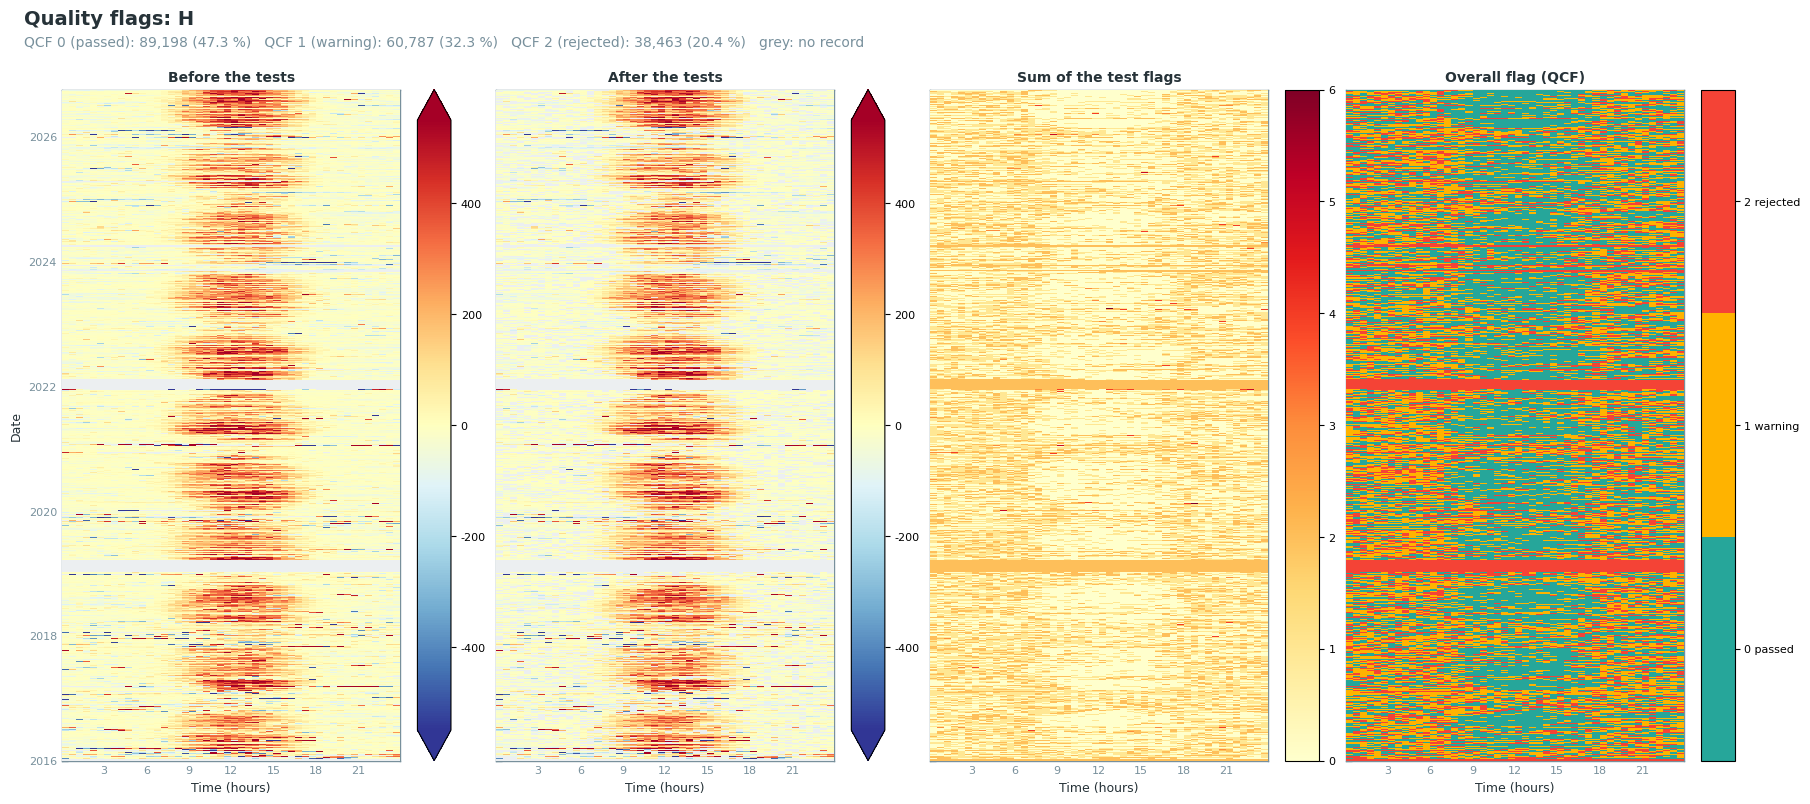

In [8]:
data.levels.level2_qcf.showplot_qcf_heatmaps()

### 📋 Table: result of each Level-2 test

In [9]:
data.levels.level2_qcf.report_qcf_flags()

Test flags: H
Measured records: 179,251 of 188,448
Missing records: 9,197 (4.88 %), flagged by the missing-values test
                                                             Pass     Warn     Fail    Fail      Not
Test                                   Period    Tested       (0)      (1)      (2)       %   tested
────────────────────────────────────────────────────────────────────────────────────────────────────
L2_H_SSITC                             all      179,251    89,576   61,082   28,593   15.95        0
                                       day       90,674    53,450   25,758   11,466   12.65        0
                                       night     88,577    36,126   35,324   17,127   19.34        0
                                                                                                    
L2_H_SCF                               all      179,251   179,251        0        0    0.00        0
                                       day       90,674    90,674        0        0    0.00        0
                                       night     88,577    88,577        0        0    0.00        0
                                                                                                    
L2_H_T_SONIC_VM97_SPIKE_HF             all      179,251   178,568        0      683    0.38        0
                                       day       90,674    90,319        0      355    0.39        0
                                       night     88,577    88,249        0      328    0.37        0
                                                                                                    
L2_H_T_SONIC_VM97_DROPOUT_HF           all      179,251   179,251        0        0    0.00        0
                                       day       90,674    90,674        0        0    0.00        0
                                       night     88,577    88,577        0        0    0.00        0
                                                                                                    
L2_H_T_SONIC_VM97_ABSOLUTE_LIMITS_HF   all      179,251   179,064        0      187    0.10        0
                                       day       90,674    90,585        0       89    0.10        0
                                       night     88,577    88,479        0       98    0.11        0

## Step 3: no storage term (Level 3.1)

`H` is the turbulent flux without a storage term, as in FLUXNET2015 and ONEFlux (Pastorello et al.
2020). Levels 3.2 and 3.3 need Level 3.1, so `run_level31` runs with `set_storage_to_zero=True`:
the column `H_L3.1` equals `H`. The single-point storage term of `H` in the EddyPro output
(`SH_SINGLE`) is not used.

In [10]:
data = run_level31(data, set_storage_to_zero=True, gapfill_storage_term=False)
print(f'After L3.1: {data.filteredseries.dropna().count():,} valid records '
      f'(col: {data.filteredseries.name})')

────────────────────────────────── Level 3.1: Storage Correction ───────────────────────────────────

> Calculating storage-corrected flux H_L3.1 from flux H + storage term set to zero

After L3.1: 149,985 valid records (col: H_L3.1_QCF)


## Step 4: outlier removal (Level 3.2)

Four tests:

1. Remove the periods in `REMOVE_DATES` by hand, see *Data sources*. Skipped when the processed years
   do not include them.
2. Absolute limits: remove values outside `ABSLIM`, -200 to 800 W m-2. The upper limit keeps the
   largest daytime values that agree with the incoming radiation, up to about 800 W m-2 at less than
   0.8 times `SW_IN` in spring before leaf-out; the lower limit lies below the nighttime values of
   summer, 99 % of which are above -170 W m-2, and removes the large negative values of wet and
   freezing episodes in winter. The limits catch extreme values in periods that the Hampel filters
   cannot judge, because the bad values fill their window.
3. Hampel filter on the double differences of neighbouring records. It finds single spikes.
4. Hampel filter on the values per time of day. Each record is compared with the records of the
   same half-hour, and of the half-hours before and after it, over 13 days. It finds values that
   are wrong for their time of day and runs of high values that the double differences do not
   catch.

Both Hampel filters use 5.5 sigma by day and by night, over 13 days, as in the CO2 flux notebook.
Negative nighttime values are not tested: a negative `H` at night is physical.

Each test first draws its plot. Check the plot, then run the cell below it, `sod.addflag()`, to
accept the test. A test that is not accepted removes nothing.

diive has more outlier tests. The table at the end of this step lists them. To add one, call its
method on `sod` in a new cell before *Apply the Level-3.2 flags*, check its plot, and accept it with
`sod.addflag()` in the cell after it.

In [11]:
data, sod = make_level32_detector(data)

### 📊 Plot: periods removed by hand

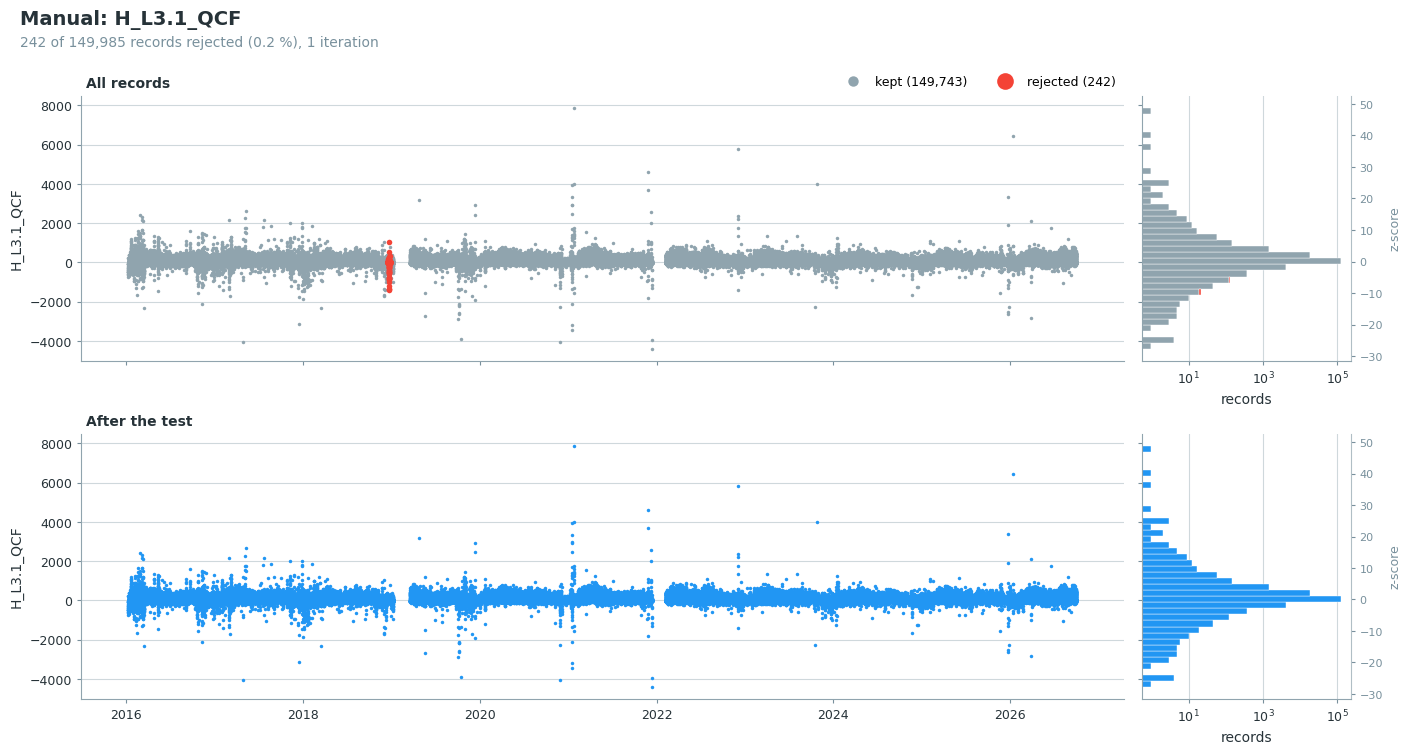

In [12]:
# Only the date ranges that overlap the processed records; none means no test and no flag.
_first, _last = data.full_df.index[0], data.full_df.index[-1]
_remove = [_d for _d in REMOVE_DATES
           if pd.Timestamp(_d[0]) <= _last and pd.Timestamp(_d[1]) + pd.Timedelta('1D') > _first]
if _remove:
    sod.flag_manualremoval_test(remove_dates=_remove, showplot=True, verbose=True)
else:
    print(f"No manual removal dates in {_first:%Y-%m-%d} - {_last:%Y-%m-%d}; test skipped.")

In [13]:
if _remove:
    sod.addflag()  # accept the manual removal

> ++Added flag column FLAG_L3.2_H_L3.1_QCF_OUTLIER_MANUAL_TEST to flag data

### 📊 Plot: absolute limits

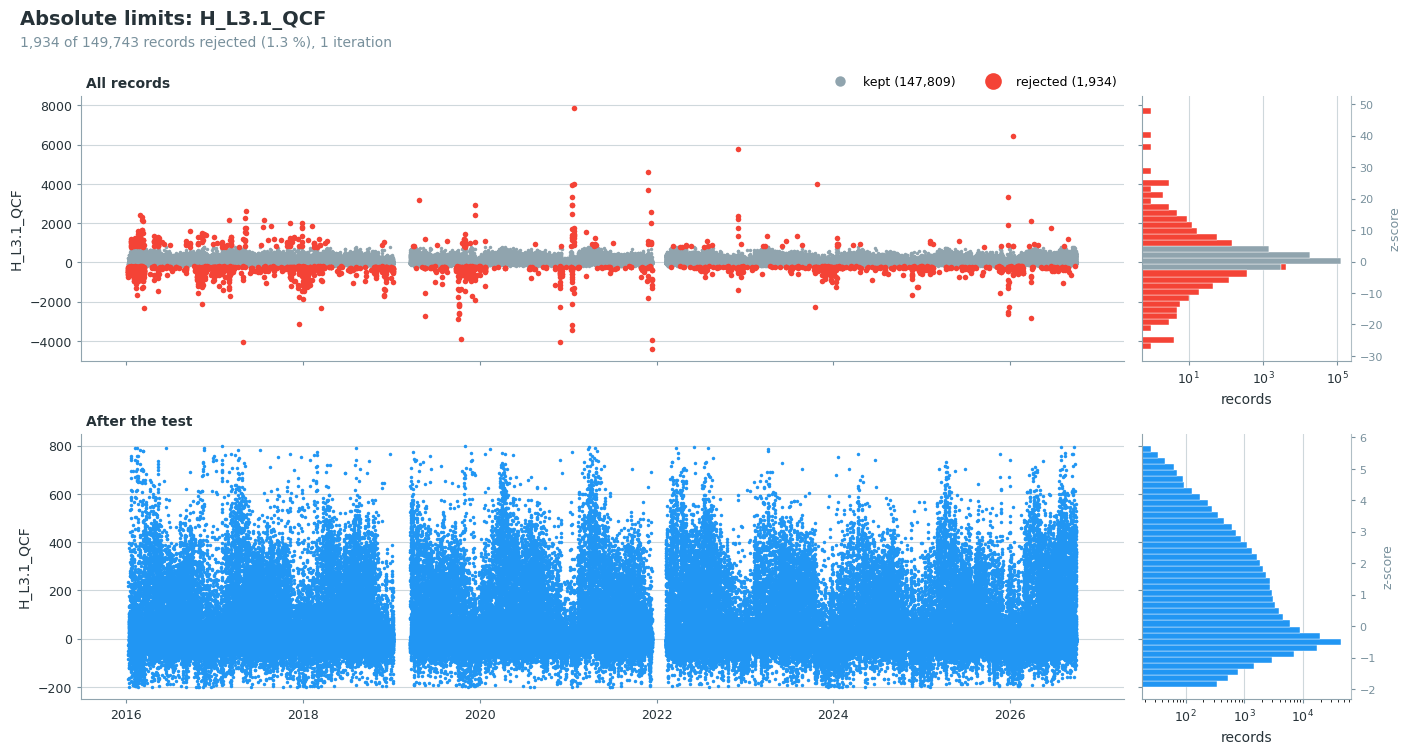

In [14]:
sod.flag_outliers_abslim_test(minval=ABSLIM[0], maxval=ABSLIM[1], showplot=True, verbose=True)

In [15]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_H_L3.1_QCF_OUTLIER_ABSLIM_TEST to flag data

### 📊 Plot: Hampel filter on double differences

[Dt/Nt] ITER #01 | Outliers:  3515 (  2.38%) | Day:  1222 | Night:  2293

[Dt/Nt] ITER #02 | Outliers:   471 (  0.33%) | Day:   181 | Night:   290

[Dt/Nt] ITER #03 | Outliers:    95 (  0.07%) | Day:    28 | Night:    67

[Dt/Nt] ITER #04 | Outliers:    33 (  0.02%) | Day:     9 | Night:    24

[Dt/Nt] ITER #05 | Outliers:     5 (  0.00%) | Day:     4 | Night:     1

[Dt/Nt] ITER #06 | Outliers:     0 (  0.00%) | Day:     0 | Night:     0

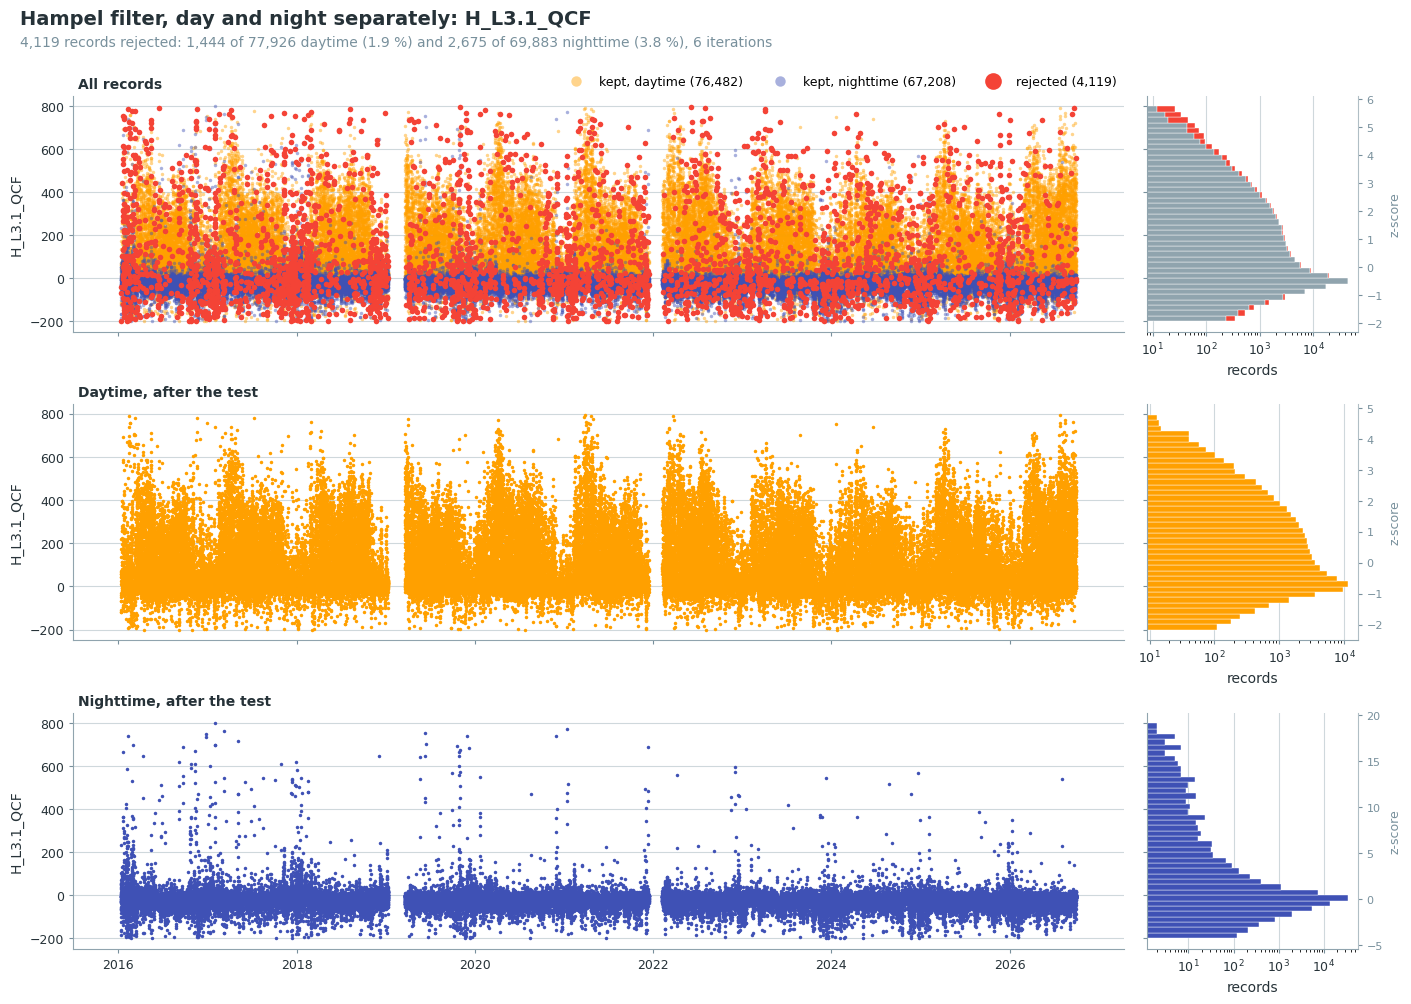

In [16]:
sod.flag_outliers_hampel_test(window_length=48 * 13, n_sigma=5.5, use_differencing=True,
                              separate_day_night=True, showplot=True, verbose=True, repeat=True)

In [17]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_H_L3.1_QCF_OUTLIER_HAMPEL_TEST to flag data

### 📊 Plot: Hampel filter on values per time of day

[Dt/Nt] ITER #01 | Outliers:  2215 (  1.54%) | Day:   625 | Night:  1590

[Dt/Nt] ITER #02 | Outliers:   323 (  0.23%) | Day:    84 | Night:   239

[Dt/Nt] ITER #03 | Outliers:    77 (  0.05%) | Day:    22 | Night:    55

[Dt/Nt] ITER #04 | Outliers:    21 (  0.01%) | Day:     7 | Night:    14

[Dt/Nt] ITER #05 | Outliers:     6 (  0.00%) | Day:     3 | Night:     3

[Dt/Nt] ITER #06 | Outliers:     2 (  0.00%) | Day:     1 | Night:     1

[Dt/Nt] ITER #07 | Outliers:     0 (  0.00%) | Day:     0 | Night:     0

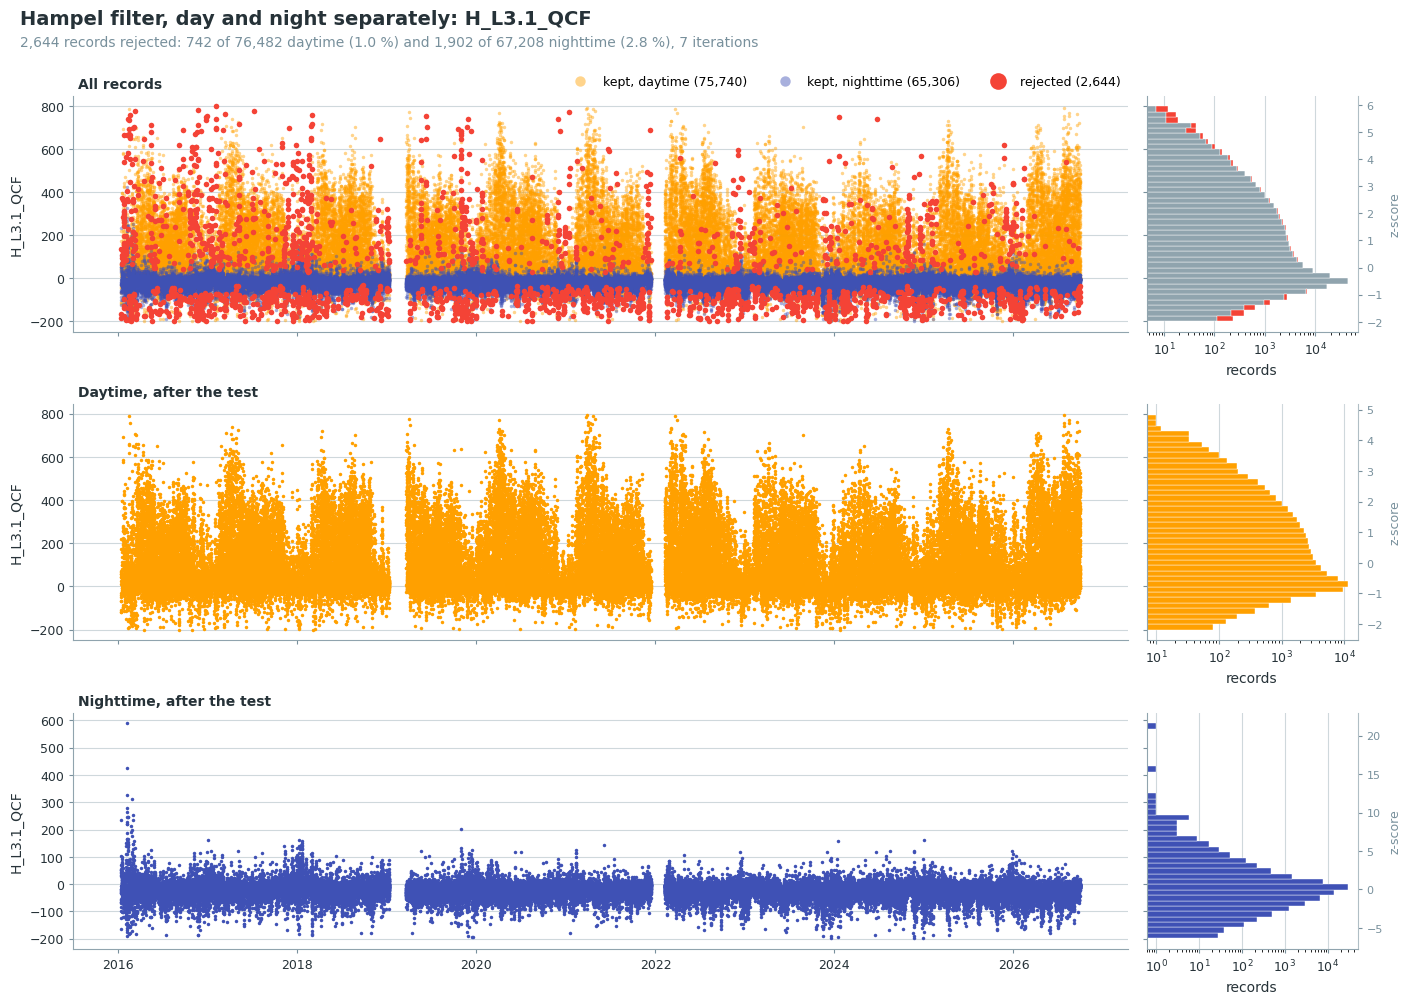

In [18]:
sod.flag_outliers_hampel_test(window_length=48 * 13, n_sigma=5.5, use_differencing=False,
                              by_time_of_day=True, time_of_day_slots=1, min_records=10,
                              separate_day_night=True, showplot=True, verbose=True, repeat=True)

In [19]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_H_L3.1_QCF_OUTLIER_HAMPEL_2_TEST to flag data

### 📋 Table: outlier tests available in diive

Every test of the outlier detector `sod`, with the ones used above marked. `help(sod.<method>)`
shows the settings of a test.

In [20]:
_used = {'flag_manualremoval_test', 'flag_outliers_abslim_test', 'flag_outliers_hampel_test'}
_rows = []
for _name in sorted(dir(type(sod))):
    if not (_name.startswith('flag_') and _name.endswith('_test')):
        continue
    # The first sentence of the docstring, which may run over two lines.
    _doc = (getattr(type(sod), _name).__doc__ or '').strip().split('\n\n')[0]
    _first = ' '.join(_doc.split()).split('. ')[0].rstrip('.')
    _rows.append({'method': f'sod.{_name}()', 'what it does': _first,
                  'used here': 'yes' if _name in _used else ''})
display(pd.DataFrame(_rows).set_index('method'))

,what it does,used here
method,,
sod.flag_manualremoval_test(),Flag specified records for removal,yes
sod.flag_missingvals_test(),Flag missing records in the data (flag 2 where...,
sod.flag_outliers_abslim_test(),Identify outliers based on absolute limits,yes
sod.flag_outliers_hampel_test(),Identify outliers in a sliding window based on...,yes
sod.flag_outliers_increments_zcore_test(),Identify outliers based on the z-score of reco...,
sod.flag_outliers_localsd_test(),Identify outliers based on standard deviation ...,
sod.flag_outliers_lof_test(),Local outlier factor detection (global or sepa...,
sod.flag_outliers_negative_night_test(),Flag nighttime values below -z times their ran...,
sod.flag_outliers_trim_low_test(),Flag values below a given absolute limit as ou...,


### Apply the Level-3.2 flags

In [21]:
data = run_level32(data, outlier_detector=sod)
print(f'After L3.2: {data.filteredseries.dropna().count():,} valid records')

────────────────────────────── Level 3.2: Stepwise Outlier Detection ───────────────────────────────

After L3.2: 141,046 valid records


### 📊 Plot: all removed outliers

Every record Level 3.2 removed, coloured by the test that removed it, with the share removed per
month and per hour of the day.

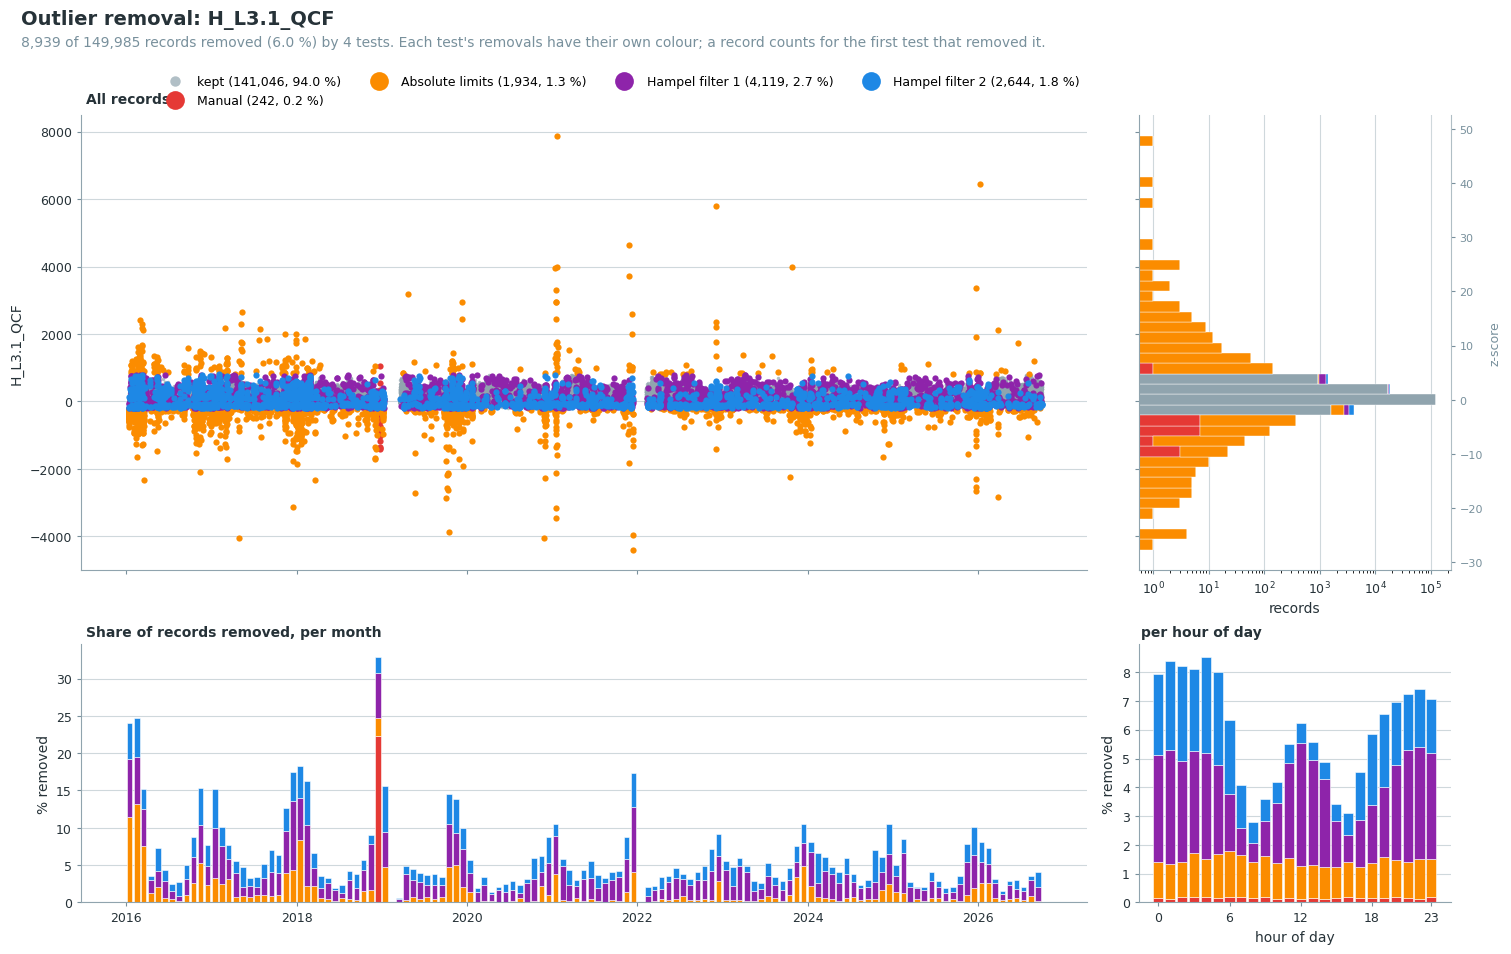

In [22]:
data.levels.level32.showplot_overview();

### 📊 Plot: Level-3.2 quality flag over time

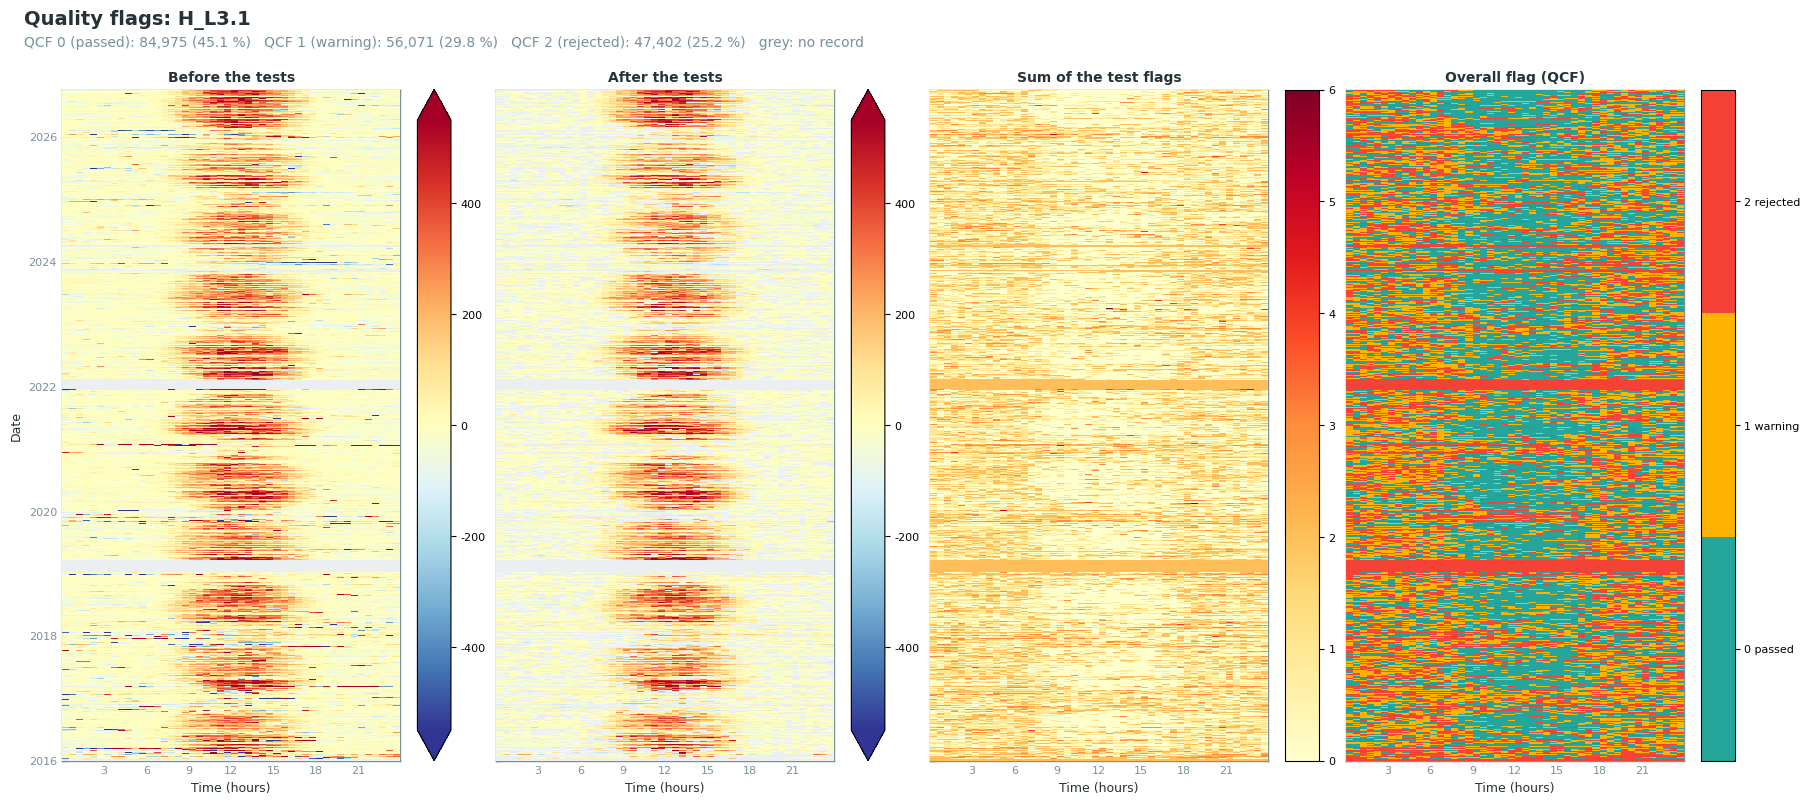

In [23]:
data.levels.level32_qcf.showplot_qcf_heatmaps()

### 📋 Table: result of each Level-3.2 test

In [24]:
data.levels.level32_qcf.report_qcf_flags()

Test flags: H_L3.1
Measured records: 179,251 of 188,448
Missing records: 9,197 (4.88 %), flagged by the missing-values test
                                                             Pass     Warn     Fail    Fail      Not
Test                                   Period    Tested       (0)      (1)      (2)       %   tested
────────────────────────────────────────────────────────────────────────────────────────────────────
L2_H_SSITC                             all      179,251    89,576   61,082   28,593   15.95        0
                                       day       90,674    53,450   25,758   11,466   12.65        0
                                       night     88,577    36,126   35,324   17,127   19.34        0
                                                                                                    
L2_H_SCF                               all      179,251   179,251        0        0    0.00        0
                                       day       90,674    90,674        0        0    0.00        0
                                       night     88,577    88,577        0        0    0.00        0
                                                                                                    
L2_H_T_SONIC_VM97_SPIKE_HF             all      179,251   178,568        0      683    0.38        0
                                       day       90,674    90,319        0      355    0.39        0
                                       night     88,577    88,249        0      328    0.37        0
                                                                                                    
L2_H_T_SONIC_VM97_DROPOUT_HF           all      179,251   179,251        0        0    0.00        0
                                       day       90,674    90,674        0        0    0.00        0
                                       night     88,577    88,577        0        0    0.00        0
                                                                                                    
L2_H_T_SONIC_VM97_ABSOLUTE_LIMITS_HF   all      179,251   179,064        0      187    0.10        0
                                       day       90,674    90,585        0       89    0.10        0
                                       night     88,577    88,479        0       98    0.11        0
                                                                                                    
L3.2_H_L3.1_QCF_OUTLIER_MANUAL         all      149,985   149,743        0      242    0.16   29,266
                                       day       78,870    78,791        0       79    0.10   11,804
                                       night     71,115    70,952        0      163    0.23   17,462
                                                                                                    
L3.2_H_L3.1_QCF_OUTLIER_ABSLIM         all      149,743   147,809        0    1,934    1.29   29,508
                                       day       78,791    77,926        0      865    1.10   11,883
                                       night     70,952    69,883        0    1,069    1.51   17,625
                                                                                                    
L3.2_H_L3.1_QCF_OUTLIER_HAMPEL         all      147,809   143,690        0    4,119    2.79   31,442
                                       day       77,926    76,482        0    1,444    1.85   12,748
                                       night     69,883    67,208        0    2,675    3.83   18,694
                                                                                                    
L3.2_H_L3.1_QCF_OUTLIER_HAMPEL_2       all      143,690   141,046        0    2,644    1.84   35,561
                                       day       76,482    75,740        0      742    0.97   14,192
                                       night     67,208    65,306        0    1,902    2.83   21,369

## Step 5: no USTAR filter (Level 3.3)

The USTAR filter is not applied to `H`, as in FLUXNET2015 and ONEFlux (Pastorello et al. 2020):
there is no evidence that the advection that biases the CO2 flux at low turbulence also affects the
energy fluxes, which are small when advection is large, at night. Level 4.1 reads the series of
Level 3.3, so the chain runs Level 3.3 with one scenario, `CUT_NONE`, at a threshold of
0 m s-1. It removes no record, also none without USTAR. This is the way diive provides for energy
fluxes. From here on `data.filteredseries` is empty, the series is held under the scenario
`CUT_NONE`, and the column names carry `_L3.3_CUT_NONE_`.

In [25]:
data = run_level33_constant_ustar(
    data,
    thresholds=USTAR_THRESHOLDS,
    threshold_labels=USTAR_SCENARIOS,
    showplot=False,
    verbose=True,
)

──────────────────────────────────── Level 3.3: USTAR Filtering ────────────────────────────────────

> QCF computed for USTAR scenario CUT_NONE

### Records for gap-filling and highest-quality records

After Level 3.3 every measured record that failed a test is removed. What is left depends on the
quality flags that are accepted (`DAYTIME_ACCEPT_QCF_BELOW` and `NIGHTTIME_ACCEPT_QCF_BELOW`, here 2,
so QCF 0 and 1). These records are what the gap-filling starts from.

The highest-quality records (QCF 0) passed every test without a warning. Use them for analyses that
need measured values only, without gap-filled ones. The output file holds them in the column ending
in `_L3.3_CUT_NONE_QCF0`; the records for gap-filling end in `_L3.3_CUT_NONE_QCF`.

### 📋 Table: records for gap-filling

In [26]:
report_gapfilling_input(data);

Records for gap-filling
                      removed:   removed:              used:    used:    used:    used:
USTAR      measured      tests      USTAR      used    QCF 0    QCF 1      day    night
───────────────────────────────────────────────────────────────────────────────────────
CUT_NONE    179,251     38,205          0   141,046   84,975   56,071   75,740   65,306
                95%        20%         0%       75%      45%      30%      40%      35%
Records, and their share of all 188,448 records of the period.
removed: tests = quality tests and outlier detection (Levels 2 to 3.2).
used = records for gap-filling: QCF below 2 by day and below 2 by night. QCF 0 is the highest 
quality, the measured flux for analyses without gap-filled values.

### 📊 Plot: records for gap-filling and highest-quality records

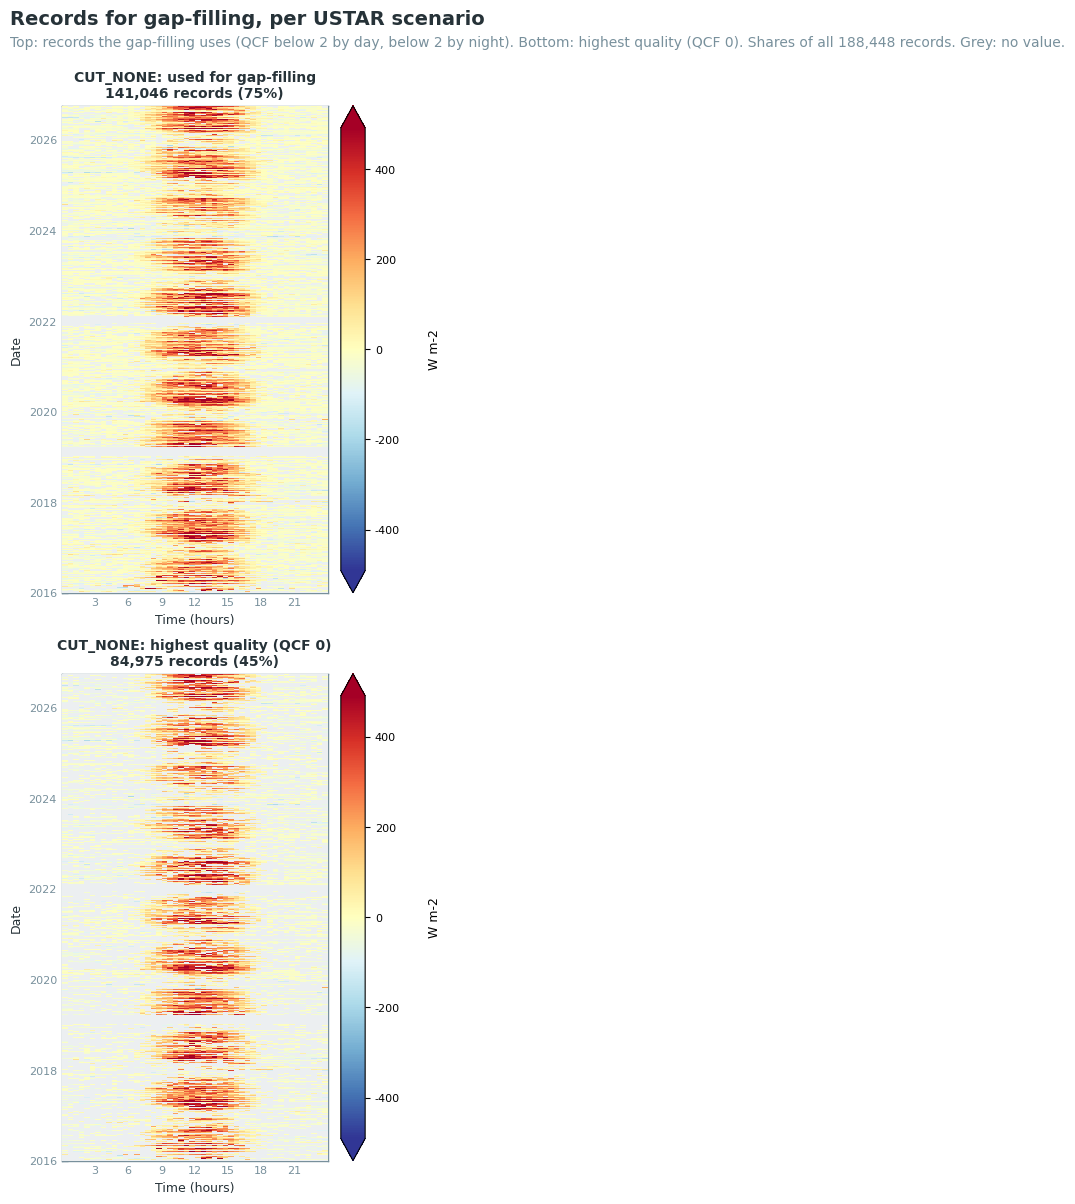

In [27]:
plot_gapfilling_input(data, units=FLUX_UNITS)

### 📋 Table: gaps to fill

The gaps left after Level 3.3, which the gap-filling has to fill. A long gap lasts at least one day.

In [28]:
report_gaps(data, long_gap_days=1);

Gaps to fill
USTAR      missing %    gaps   long gaps   longest gap (days)   worst month   worst month missing %
───────────────────────────────────────────────────────────────────────────────────────────────────
CUT_NONE        25.2   22849          13                 69.2           Jan                    42.3
A long gap lasts at least 1 day.

## Step 6: model features

The feature engineer adds lagged values, rolling statistics and time terms to the three meteo
drivers. It is built once and passed to XGBoost. `target_col` is only a placeholder.

In [29]:
engineer = FeatureEngineer(
    target_col='_target_',
    features_lag=[-2, 2],
    features_lag_stepsize=1,
    features_rolling=[2, 4, 12, 24, 48],
    features_rolling_stats=['median', 'min', 'max', 'std'],
    features_ema=[6, 12, 24, 48],
    vectorize_timestamps=True,
    add_continuous_record_number=True,
    sanitize_timestamp=True,
    verbose=0,
)

## Step 7: gap-filling (Level 4.1)

Two methods fill the gaps: XGBoost, the gap-filling method of the CO2 flux of this dataset, and MDS,
the method of FLUXNET2015 and ONEFlux for the energy fluxes (Pastorello et al. 2020). Step 10
compares the two.

### XGBoost

Each year gets its own model, trained on that year and its two neighbouring years. SHAP values
select the features: a feature is kept if it is clearly more important than a random variable.

In [30]:
data = run_level41_xgb(
    data,
    features=FEATURES,
    engineer=engineer,
    reduce_features=True,
    verbose=1,
    **XGB_SETTINGS,
)

───────────────────────────────── Level 4.1: Gap-Filling (XGBoost) ─────────────────────────────────

### MDS

Marginal distribution sampling (Reichstein et al. 2005) fills each gap with the mean of measured
fluxes under similar conditions: incoming radiation, air temperature and VPD within set
tolerances, in a time window that widens until enough similar records are found. `mode='diive'`
takes a symmetric mean by day (Vekuri et al. 2023) and fills every gap, also long ones, because
this dataset needs complete years. Only measured driver values serve as similar records (the
`ISFILLED` flags of the drivers). MDS predicts each measured record without using it, so its
scores are out-of-sample.

**Skipped** when `RUN_MDS = False`.

In [31]:
if RUN_MDS:
    data = run_level41_mds(
        data,
        swin=SW_IN_F, ta=TA_F, vpd=VPD_F,  # W m-2, degC, kPa
        swin_qc=SW_IN_FLAG, ta_qc=TA_FLAG, vpd_qc=VPD_FLAG,
        **MDS_SETTINGS,
    )

─────────────────────────────────── Level 4.1: Gap-Filling (MDS) ───────────────────────────────────

## Step 8: results

How many records were measured and how many were filled, then the annual sum of the flux. In 2019
there is no `H` from 10 January to 20 March (69 days), and in 2022 none before 7 February, so
these sums rest partly on the model. 2026 ends on 30 September.

### 📋 Table: measured and filled records

In [32]:
report_gapfilling_variables(data)

Gap-filled variables
method    USTAR      records   measured   filled   filled %
───────────────────────────────────────────────────────────
MDS       CUT_NONE   188,448    141,046   47,402       25.2
XGBoost   CUT_NONE   188,448    141,046   47,402       25.2
MDS (CUT_NONE): H_L3.1_L3.3_CUT_NONE_QCF -> H_L3.1_L3.3_CUT_NONE_QCF_gfMDS
XGBoost (CUT_NONE): H_L3.1_L3.3_CUT_NONE_QCF -> H_L3.1_L3.3_CUT_NONE_QCF_gfXG

### 📋 Table: annual sums of the flux

In [33]:
report_annual_sums(data, gain=WM2_TO_MJ, units='MJ m-2');

Annual sums (MJ m-2)
                 MDS       XGBoost
year        CUT_NONE      CUT_NONE
──────────────────────────────────
2016     1,070 (72%)   1,129 (72%)
2017     1,295 (75%)   1,308 (75%)
2018     1,283 (75%)   1,299 (75%)
2019     1,153 (61%)   1,174 (61%)
2020     1,380 (81%)   1,382 (81%)
2021     1,221 (75%)   1,209 (75%)
2022     1,443 (72%)   1,431 (72%)
2023     1,016 (78%)   1,022 (78%)
2024       800 (76%)     795 (76%)
2025     1,067 (79%)   1,053 (79%)
2026 *   1,365 (81%)   1,365 (81%)
In brackets: the share of the year's records that were measured.
* Incomplete year (2026): the sum covers only part of it.

## Step 9: model quality

First the scores on test data: a random 25 % of the complete records, which the model did not see in
training. Early stopping uses a part of the training data, not the test data. Because the test
records lie between training records, the scores describe short gaps better than gaps of several
days.

### 📋 Table: scores on test data

In [34]:
report_traintest_model_scores(data)

Held-out test scores
method    USTAR      year      R²    RMSE     MAE   MedAE    MaxE
─────────────────────────────────────────────────────────────────
XGBoost   CUT_NONE   2016   0.821   50.55   30.54   17.06   726.6
XGBoost   CUT_NONE   2017   0.821   50.55   30.54   17.06   726.6
XGBoost   CUT_NONE   2018   0.842   48.39   29.15   16.36   689.9
XGBoost   CUT_NONE   2019   0.878   43.21   27.43   16.37   417.2
XGBoost   CUT_NONE   2020   0.875   44.08   27.74   15.82   546.7
XGBoost   CUT_NONE   2021   0.888   44.78   27.85   15.80   474.7
XGBoost   CUT_NONE   2022   0.884   42.85   27.09   15.71   723.9
XGBoost   CUT_NONE   2023   0.878   41.76   26.49   15.56   313.6
XGBoost   CUT_NONE   2024   0.868   40.19   25.51   15.23   494.2
XGBoost   CUT_NONE   2025   0.878   43.74   28.02   16.50   431.9
XGBoost   CUT_NONE   2026   0.878   43.74   28.02   16.50   431.9
XGBoost   CUT_NONE   mean   0.865   44.89   28.03   16.18   543.4
Test set: a random share of the complete records, not used in training.
Errors are in the units of the flux.
Not available for MDS (CUT_NONE).

### 📋 Table: gap-filling models per year

How each model was built and how well it did: the years it was trained on, its features, the
training and test records, the number of trees early stopping chose, the records of the final fit,
the test scores, and how the gaps of its year were filled.

In [35]:
report_model_overview(data);

Gap-filling models
                trained                                         final    test   test            fal…
USTAR     ye…   on         featur…    train    test     trees     fit      R²   RMSE   filled   back
────────────────────────────────────────────────────────────────────────────────────────────────────
CUT_NO…   20…   2016-20…        94   29,121   9,707   349/350   38,8…   0.821   50.…    4,963      0
CUT_NO…   20…   2016-20…        94   29,121   9,707   349/350   38,8…   0.821   50.…    4,373      0
CUT_NO…   20…   2017-20…        94   27,717   9,240   346/350   36,9…   0.842   48.…    4,444      0
CUT_NO…   20…   2018-20…        94   28,481   9,494   331/350   37,9…   0.878   43.…    6,786      0
CUT_NO…   20…   2019-20…        94   28,470   9,490   222/350   37,9…   0.875   44.…    3,403      0
CUT_NO…   20…   2020-20…        94   29,928   9,977   272/350   39,9…   0.888   44.…    4,459      0
CUT_NO…   20…   2021-20…        94   29,550   9,850   282/350   39,4…   0.884   42.…    4,841      0
CUT_NO…   20…   2022-20…        94   29,783   9,928   349/350   39,7…   0.878   41.…    3,860      0
CUT_NO…   20…   2023-20…        94   30,700   10,2…       350   40,9…   0.868   40.…    4,196      0
CUT_NO…   20…   2024-20…        94   28,439   9,480   200/350   37,9…   0.878   43.…    3,618      0
CUT_NO…   20…   2024-20…        94   28,439   9,480   200/350   37,9…   0.878   43.…    2,459      0
Each year has its own model, trained on that year and its neighbours ('trained on').
train / test: a random 75 / 25 % split of the complete records; the test scores come from the 25 %, 
which the model did not see.
trees: with early stopping, the number it chose on 10 % of the training records, out of the maximum;
at the maximum, more trees might still help.
final fit: the gaps are filled by a model refitted on all complete records with that number of 
trees. filled / fallback: gaps of the model year filled by this model, or by the fallback model on 
timestamp features where a driver was missing.
1 model(s) used all trees: early stopping did not stop them.
XGBoost: early_stopping_rounds=10, learning_rate=0.05, max_depth=6, n_estimators=350, n_jobs=-1, 
random_state=42

Next the scores on all measured records. The gaps are filled by a model refitted on all of them, so
these scores are better than the test scores and only show how closely the model fits.

### 📋 Table: scores on all measured records

In [36]:
report_gapfilling_model_scores(data)

In-sample scores
method    USTAR      year      R²    RMSE     MAE   MedAE    MaxE
─────────────────────────────────────────────────────────────────
MDS       CUT_NONE   all    0.837   49.97   31.34   18.19   709.8
XGBoost   CUT_NONE   2016   0.903   37.55   24.62   15.46   471.0
XGBoost   CUT_NONE   2017   0.903   37.55   24.62   15.46   471.0
XGBoost   CUT_NONE   2018   0.916   34.95   23.26   14.94   368.8
XGBoost   CUT_NONE   2019   0.927   33.42   22.50   14.52   386.4
XGBoost   CUT_NONE   2020   0.923   34.53   23.00   14.63   474.7
XGBoost   CUT_NONE   2021   0.935   33.59   22.63   14.44   298.3
XGBoost   CUT_NONE   2022   0.932   33.19   22.39   14.55   420.2
XGBoost   CUT_NONE   2023   0.933   31.00   21.33   14.15   345.8
XGBoost   CUT_NONE   2024   0.926   30.17   20.80   14.01   335.6
XGBoost   CUT_NONE   2025   0.919   35.13   23.94   15.57   276.4
XGBoost   CUT_NONE   2026   0.919   35.13   23.94   15.57   276.4
XGBoost   CUT_NONE   mean   0.921   34.20   23.00   14.84   375.0
Model predictions against every measured record, training records included, so optimistic for the ML
methods.
MDS predicts each measured record without using it, so its scores are out-of-sample and not 
comparable with those of the ML methods; report_gapfilling_comparison scores both on the same 
held-out records.
Errors are in the units of the flux.

### 📋 Table: years used to train each year's model

In [37]:
report_gapfilling_poolyears(data)

Years pooled for each year's model
model year   trained on, all ML runs
────────────────────────────────────
2016         2016-2018              
2017         2016-2018              
2018         2017-2019              
2019         2018-2020              
2020         2019-2021              
2021         2020-2022              
2022         2021-2023              
2023         2022-2024              
2024         2023-2025              
2025         2024-2026              
2026         2024-2026              
Not available for MDS (CUT_NONE) (does not pool years).

### 📋 Table: most important features (SHAP)

In [38]:
report_gapfilling_feature_importances(data, ustar_scenario=SCENARIO)

Feature importances, XGBoost (CUT_NONE): top 10 of 94 features, mean |SHAP|
 #   fea…    2016   2017    2018   2019    2020   2021    2022   2023    2024   2025    2026    mean
────────────────────────────────────────────────────────────────────────────────────────────────────
 1   SW_…   51.7…   51.…   47.9…   57.…   54.4…   58.…   50.0…   44.…   42.8…   42.…   42.8…   49.5…
 2   .SW…   16.4…   16.…   19.2…   21.…   21.5…   23.…   28.0…   22.…   20.6…   21.…   21.0…   21.1…
 3   .SW…   3.969   3.9…   4.461   3.5…   7.639   8.3…   7.108   10.…   9.283   19.…   19.3…   8.850
 4   .DO…   6.988   6.9…   6.572   7.6…   5.142   5.5…   5.213   5.2…   7.127   9.7…   9.737   6.913
 5   .SW…   4.354   4.3…   3.921   3.8…   5.708   3.4…   3.425   2.6…   2.803   3.1…   3.122   3.699
 6   .HO…   6.530   6.5…   6.844   4.4…   3.073   2.8…   1.001   0.8…   0.692   0.4…   0.460   3.072
 7   .SW…   3.435   3.4…   3.176   1.0…   0.768   3.2…   4.916   4.9…   2.238   0.9…   0.941   2.643
 8   .VP…   2.652   2.6…   1.833   3.7…   2.929   1.8…   1.381   1.9…   2.099   1.1…   1.141   2.127
 9   .DO…   1.714   1.7…   2.472   3.0…   2.121   1.5…   2.042   1.7…   1.864   1.9…   1.935   2.016
10   .WE…   1.500   1.5…   0.300   0.8…   4.446   3.8…   3.685   1.8…   0.808   1.3…   1.390   1.957

Names starting with '.' are features engineered from the drivers (lags, rolling statistics, 
timestamp terms).
Not available for MDS (CUT_NONE) (no model trained).

### 📊 Plot: feature ranks per year

> MDS (CUT_NONE): no feature ranks available.

F:\dev\datasets\dataset_ch-lae_flux_product\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


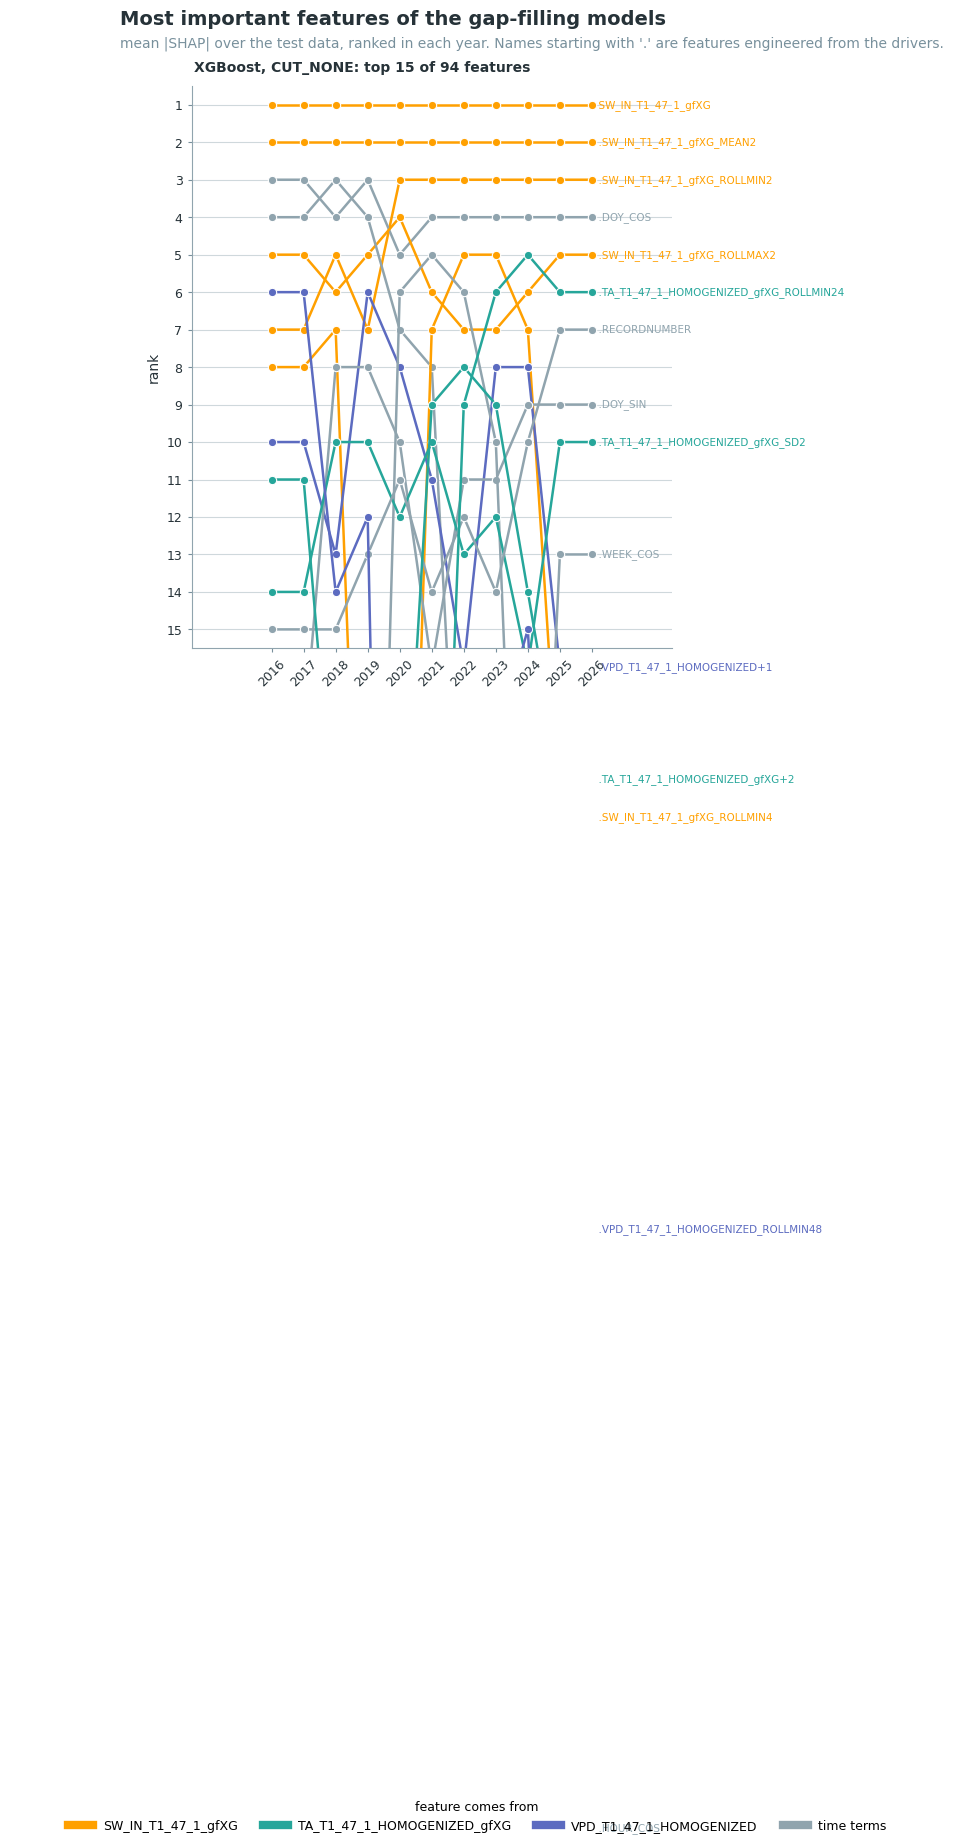

In [39]:
plot_feature_ranks_per_year(data)

## Step 10: result plots

### 📊 Plot: flux by quality class, heatmaps, XGBoost

The highest-quality records (QCF 0), the records the gap-filling used (QCF 0 and 1), the rejected
records, and the gap-filled result, on one colour scale.

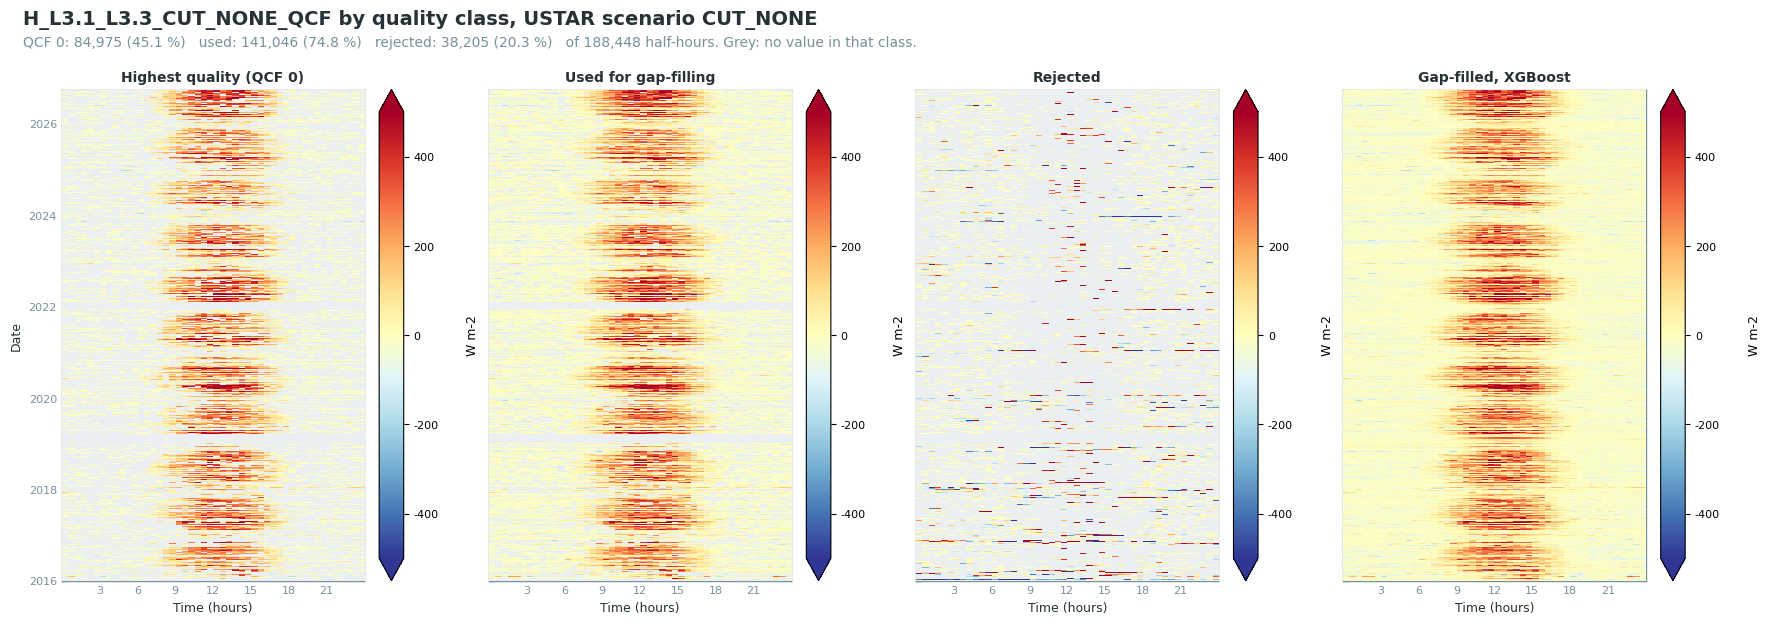

In [40]:
plot_quality_heatmaps(data, ustar_scenario=SCENARIO, units=FLUX_UNITS, method='xgb')

### 📊 Plot: flux by quality class, day and night, XGBoost

Daytime and nighttime records by quality class, then the gap-filled result, with measured and
filled records shown apart.

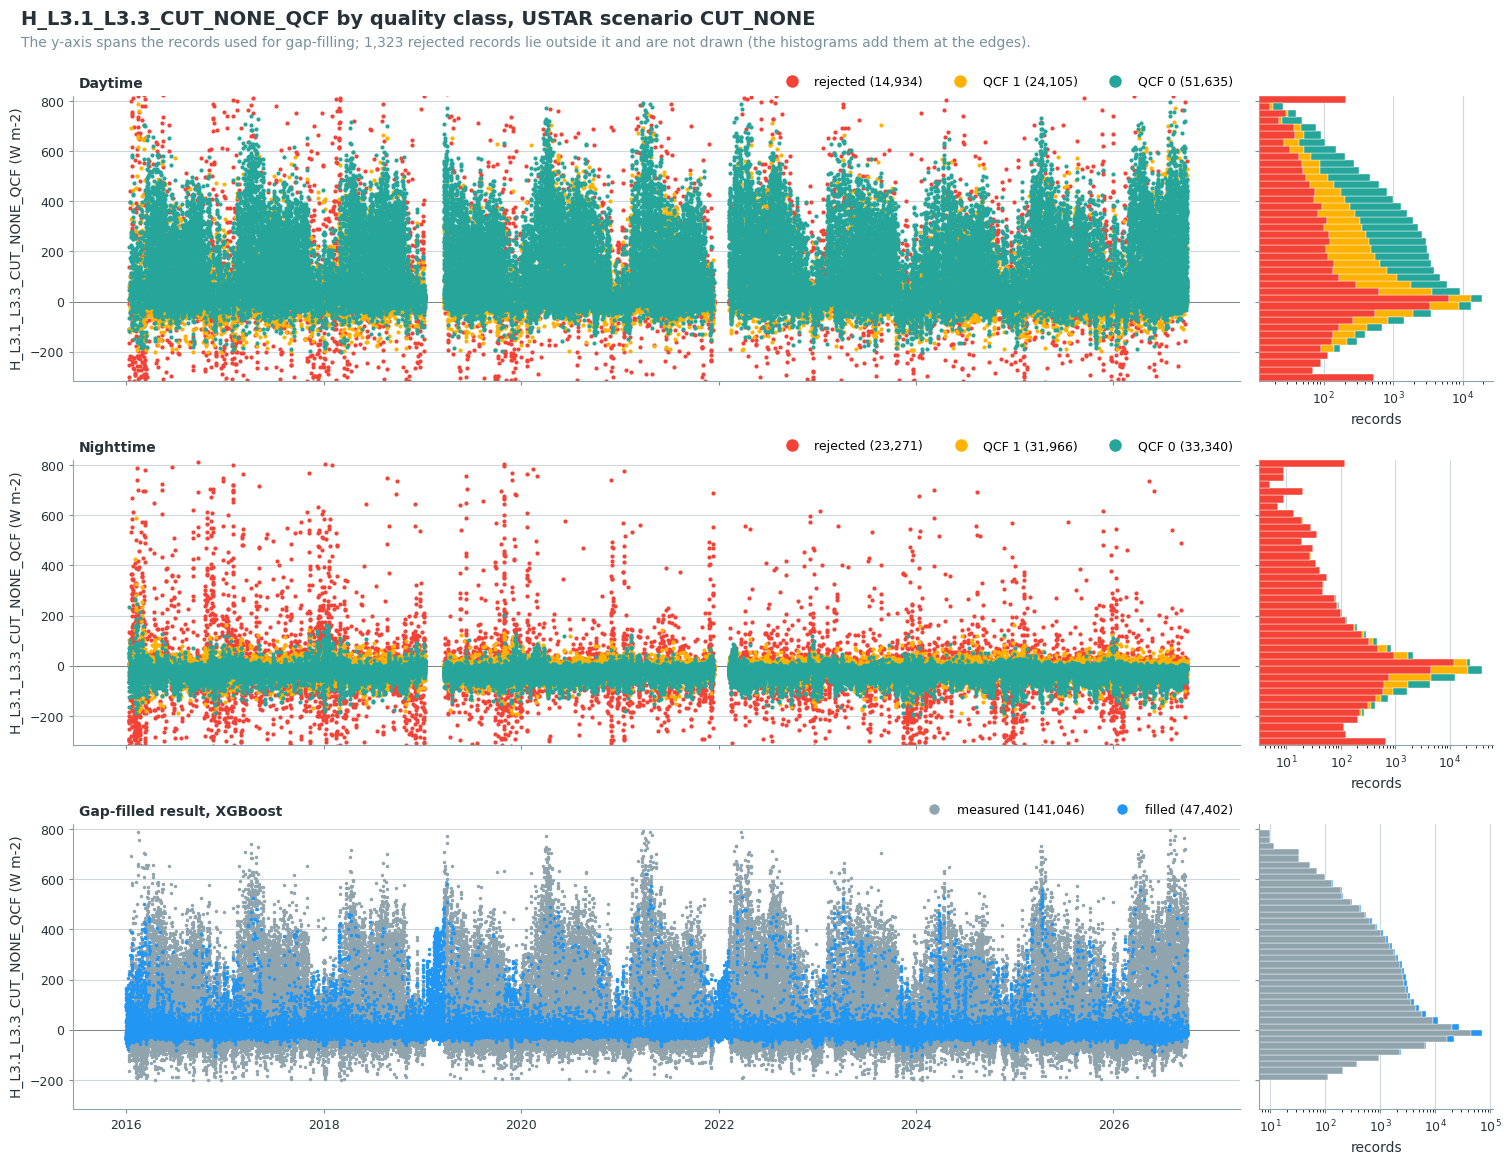

In [41]:
plot_quality_timeseries(data, ustar_scenario=SCENARIO, units=FLUX_UNITS, method='xgb')

### 📊 Plot: measured and gap-filled flux

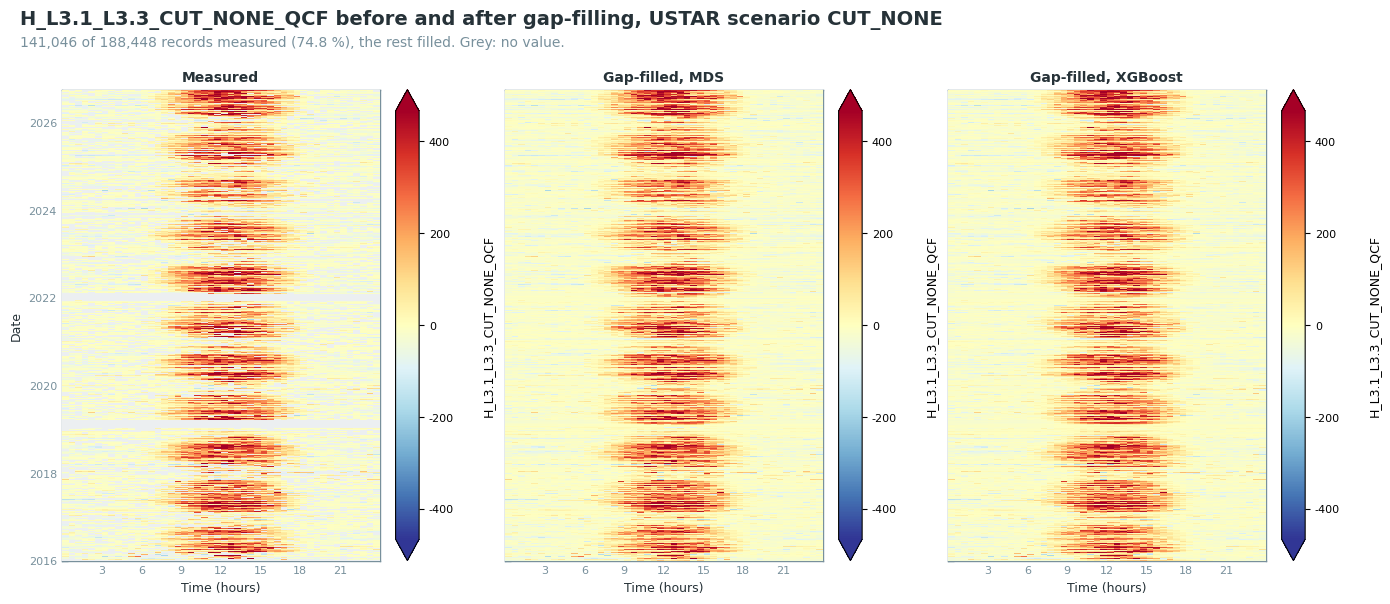

In [42]:
data.plot_gapfilled_heatmaps(ustar_scenario=SCENARIO)

### 📊 Plot: cumulative flux

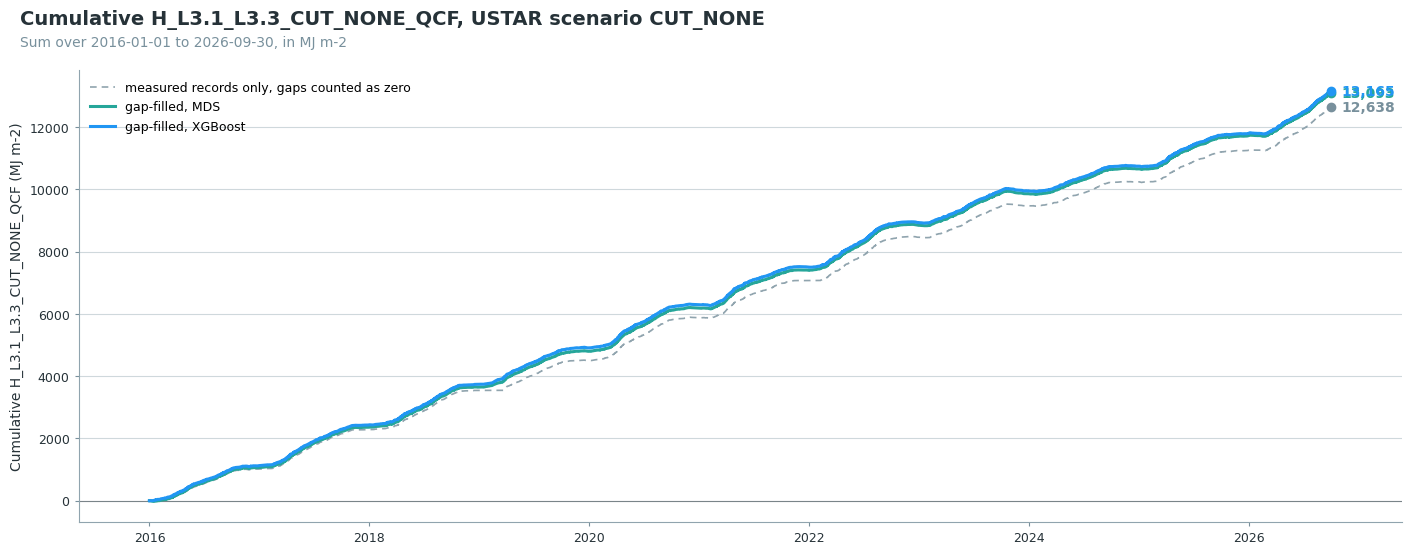

In [43]:
data.plot_cumulative_comparison(
    ustar_scenario=SCENARIO,
    conv_factor=WM2_TO_MJ,
    units='MJ m-2',
)

### 📊 Plot: cumulative flux of both gap-filling methods

One line per gap-filling method, each in its own colour, over the whole processed period.

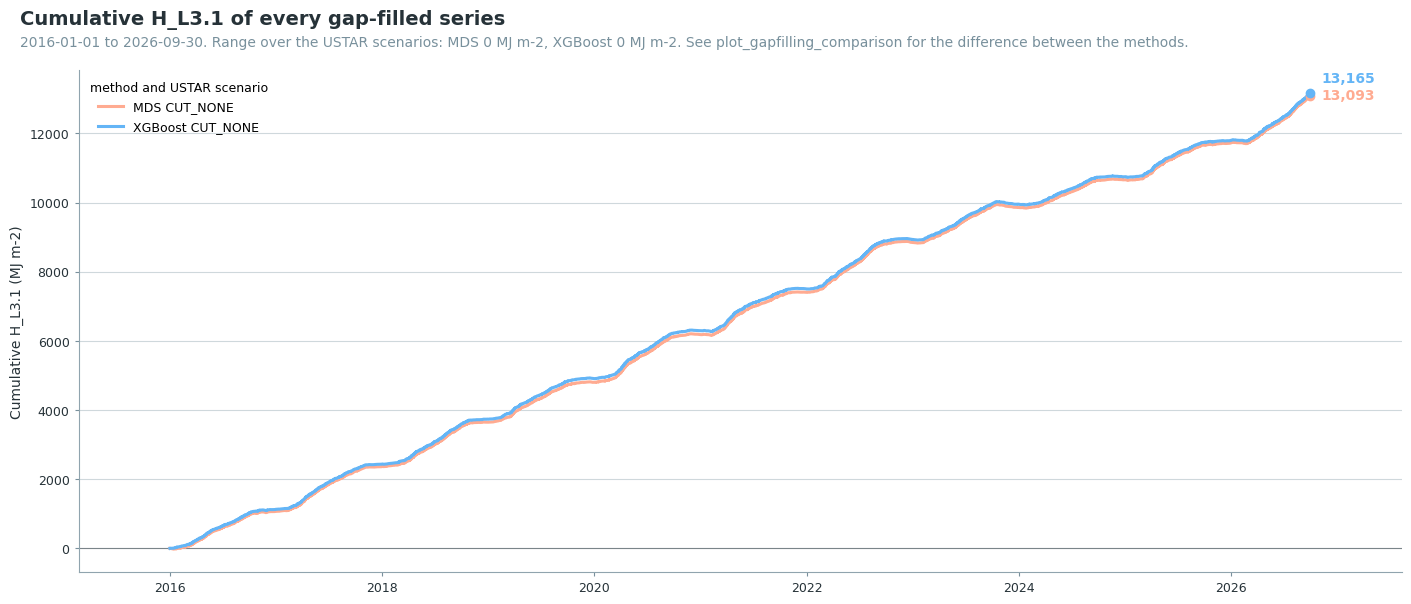

In [44]:
plot_gapfilled_cumulative(
    data,
    gain=WM2_TO_MJ,
    units='MJ m-2',
    per_year=False,
)

### 📊 Plot: cumulative flux per year

One panel per gap-filling method, on the same y-axis. One line per year, with the mean of all years
plus and minus one standard deviation as a band. 2019 has no measurements from 10 January to
20 March and 2022 none before 7 February; the model fills these periods. 2026 ends on 30 September,
so its total cannot be compared with full years, and it is left out of the mean and the band.

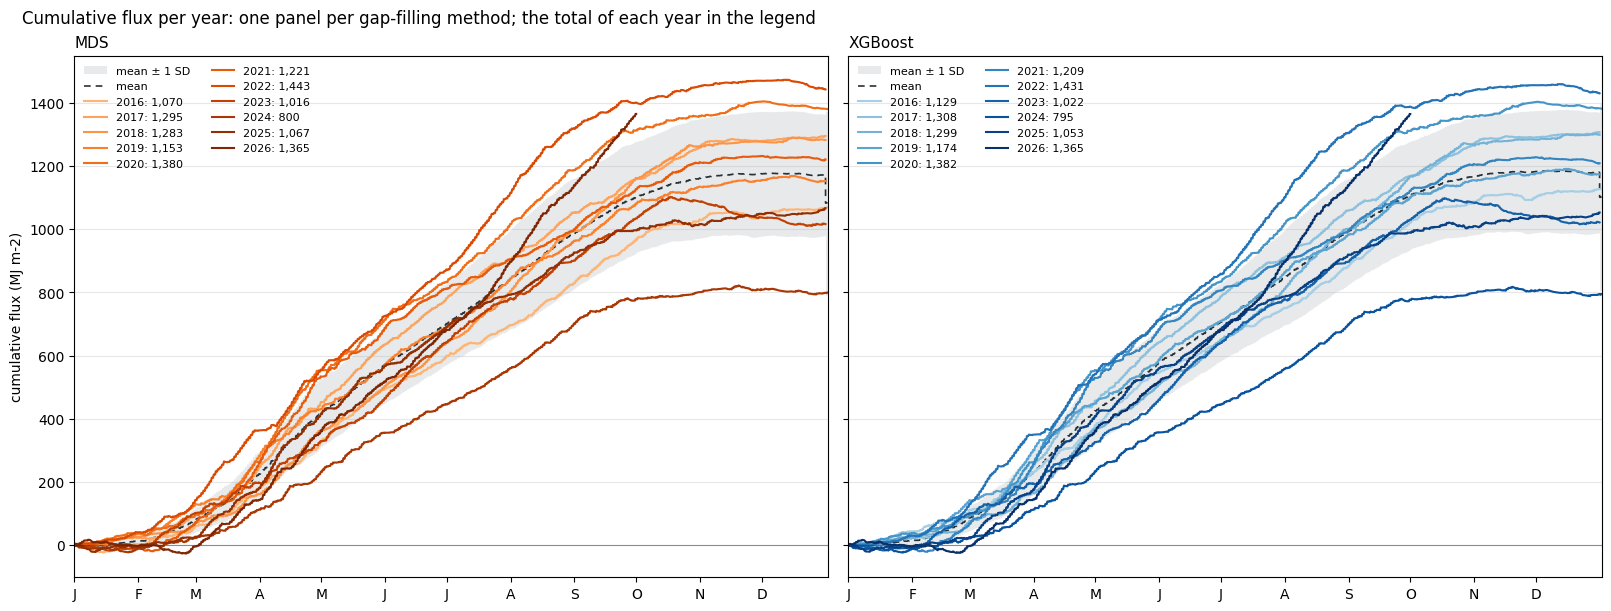

In [45]:
# One panel per gap-filling method, on a shared y-axis. Years run from light to dark, so the most
# recent year is the darkest line.
_gf = data.gapfilled_cols()
_names = {'mds': 'MDS', 'xgb': 'XGBoost', 'rf': 'random forest'}
_cmaps = {'mds': 'Oranges', 'xgb': 'Blues', 'rf': 'Greens'}
_months = [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335]
# A last year that ends before 31 December stays out of the mean and the band.
_end = data.fpc_df.index[-1]
_partial = [_end.year] if (_end.month, _end.day) != (12, 31) else None
fig, axes = plt.subplots(1, len(_gf), figsize=(8 * len(_gf), 6), sharex=True, sharey=True,
                         layout='constrained', squeeze=False)
for _ax, (_method, _cols) in zip(axes[0], _gf.items()):
    _cum = doy_cumulatives_per_year(data.fpc_df[_cols[SCENARIO]] * WM2_TO_MJ)
    _cum = _cum.loc[:, _cum.notna().any()]
    _years = list(_cum.columns)
    _shades = plt.get_cmap(_cmaps.get(_method, 'Greys'))(
        np.linspace(0.35, 1.0, len(_years)) if len(_years) > 1 else [0.85])
    if len(_years) > 1:
        _ref = doy_mean_cumulative(cumulatives_per_year_df=_cum,
                                   excl_years_from_reference=_partial)
        _ax.fill_between(_ref.index, _ref['MEAN-SD'], _ref['MEAN+SD'], color='#b0b8c0',
                         alpha=0.3, linewidth=0, label='mean ± 1 SD')
        _ax.plot(_ref.index, _ref['MEAN_DOY_TIME'], color='#263238', linewidth=1.2,
                 linestyle=(0, (4, 3)), label='mean')
    for _shade, _year in zip(_shades, _years):
        _valid = _cum[_year].dropna()
        _ax.plot(_cum.index, _cum[_year], color=_shade, linewidth=1.5,
                 label=f"{_year}: {_valid.iloc[-1]:,.0f}")
    _ax.axhline(0, color='#263238', linewidth=0.8, alpha=0.5)
    _ax.set_title(_names.get(_method, _method), loc='left', fontsize=11)
    _ax.set_xticks(_months, ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D'])
    _ax.set_xlim(1, 367)
    _ax.grid(axis='y', alpha=0.3)
    _ax.legend(frameon=False, fontsize=8, ncol=1 if len(_years) < 8 else 2, loc='upper left')
axes[0][0].set_ylabel('cumulative flux (MJ m-2)')
fig.suptitle('Cumulative flux per year: one panel per gap-filling method; the total of each year '
             'in the legend', x=0.01, ha='left', fontsize=12)
plt.show()

### Gap-filling methods compared

Both methods fill the same gaps, so the difference between their sums comes from the filled
values alone. The table splits that difference into daytime and nighttime gaps and by gap length,
and scores both methods on the same held-out records: the test records of XGBoost, which MDS also
predicts without using them. These are random single half-hours, so the scores describe short
gaps, while the sums depend more on the long ones.

**Skipped** when `RUN_MDS = False`.

#### 📋 Table: MDS and XGBoost, sums and their difference

In [46]:
if RUN_MDS:
    report_gapfilling_comparison(data, methods=('mds', 'xgb'), gain=WM2_TO_MJ, units='MJ m-2');

Gap-filling methods compared: MDS and XGBoost
              sum       sum                    from         from   gaps   gaps    gaps   gaps
USTAR         MDS   XGBoost   difference   day gaps   night gaps      1   2-12   13-48    >48
─────────────────────────────────────────────────────────────────────────────────────────────
CUT_NONE   13,093    13,165           72         93          -21     -4     13      18     45
Sums (MJ m-2). difference = XGBoost - MDS over the filled gaps, split into daytime and nighttime 
gaps and by gap length in records.
CUT_NONE, same 34,868 held-out records: MDS R² 0.84 RMSE 49.92, XGBoost R² 0.87 RMSE 45.48
Held-out records are random single half-hours, so these scores describe short gaps; the sums depend 
more on the long ones.

#### 📊 Plot: where MDS and XGBoost differ

The filled values of both methods at the same gaps, their mean difference by month and hour, the
contribution of each month to the difference of the sums, and the cumulative difference.

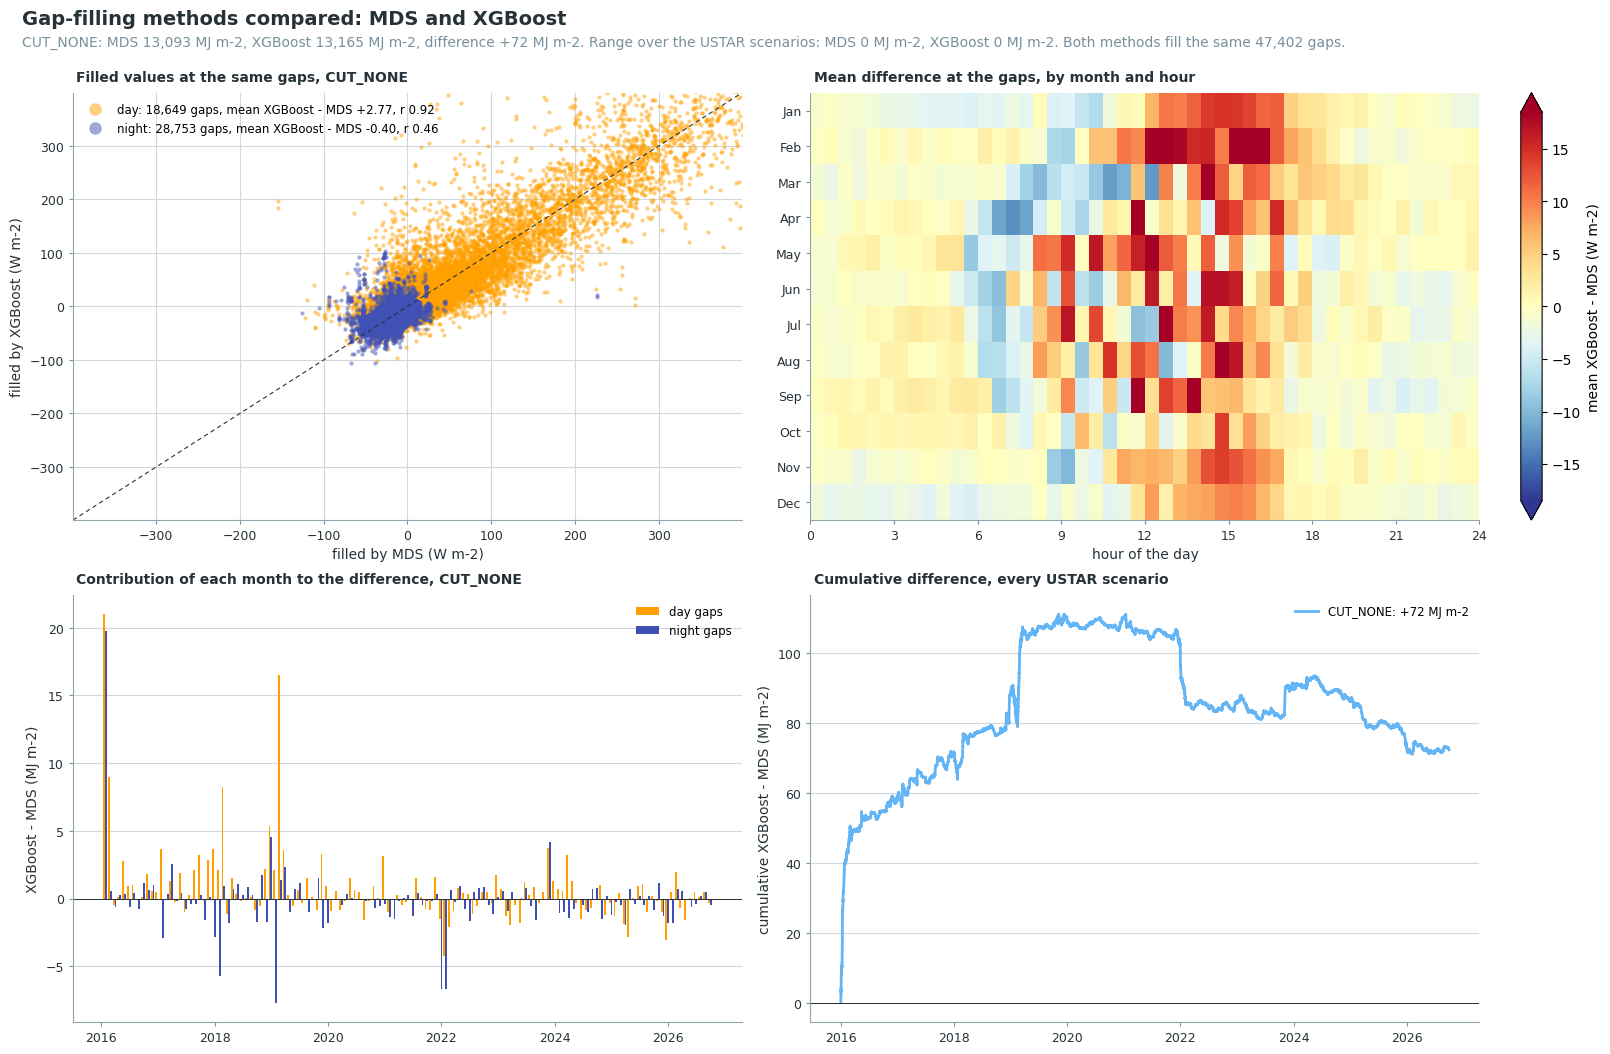

In [47]:
if RUN_MDS:
    plot_gapfilling_comparison(data, ustar_scenario=SCENARIO, methods=('mds', 'xgb'),
                               gain=WM2_TO_MJ, units='MJ m-2', flux_units=FLUX_UNITS);

## 💾 Step 11: export

The output file holds only the columns this notebook adds: the flags and series of every level and
the gap-filled flux. The input columns stay in the input file; the merge into the fullset joins the
flux outputs with it on the timestamp.

In [48]:
_all = data.merged_df()
out_df = _all[[c for c in _all.columns if c not in df.columns]]
assert out_df.index.equals(df.index), "the output timestamps differ from the input"
print(f"{out_df.shape[0]:,} records x {out_df.shape[1]} columns "
      f"(input columns left out: {_all.shape[1] - out_df.shape[1]})")
filepath = dv.save_parquet(data=out_df, filename=OUTNAME, outpath=OUTPATH)

> New variables from the flux post-processing chain: 40 (L2: 12, L3.1: 7, L3.2: 10, L3.3: 7, L4.1:
4)

> No variables in the input data were overwritten, only new variables added.

188,448 records x 43 columns (input columns left out: 347)


> Saved file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_PROCESSIN
G_CHAIN\34_IRGA72_2016-2024\15_FPPC_H_2016-2026.09.parquet (0.361 seconds).

***

# End of notebook.

In [49]:
NOTEBOOK_END = datetime.now()
_h, _rem = divmod(int((NOTEBOOK_END - NOTEBOOK_START).total_seconds()), 3600)
_m, _s = divmod(_rem, 60)

print(f"Started:  {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Finished: {NOTEBOOK_END.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Runtime:  {_h:02d}:{_m:02d}:{_s:02d} (hh:mm:ss)")

Started:  2026-10-26 15:56:35
Finished: 2026-10-26 16:01:00
Runtime:  00:04:24 (hh:mm:ss)
